In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

# 1) Load ONE session
# HRV timeline is master and temp can be NaN (we handle later in windows)
def load_session(pid: int, sid: int) -> pd.DataFrame:
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"

    hrv_file = session_dir / "chest_physiology_summary.csv"
    temp_file = session_dir / "wrist_skin_temperature.csv"

    # your special case
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"

    if not (hrv_file.exists() and temp_file.exists()):
        return pd.DataFrame()

    df_hrv = pd.read_csv(hrv_file)
    df_tmp = pd.read_csv(temp_file)

    df_hrv["timestamp"] = pd.to_datetime(df_hrv["timestamp"], unit="ms", utc=True)
    df_tmp["timestamp"] = pd.to_datetime(df_tmp["timestamp"], unit="ms", utc=True)

    hrv_1s = (df_hrv.set_index("timestamp")
                    .sort_index()
                    .resample("1s")
                    .mean(numeric_only=True))

    tmp_1s = (df_tmp.set_index("timestamp")
                    .sort_index()
                    .resample("1s")
                    .mean(numeric_only=True)
                    .rename(columns={"temp": "skin_temp", "temperature": "skin_temp"}))

    # HRV timeline is master
    merged = hrv_1s.join(tmp_1s, how="left")

    # Ensure strict 1 Hz timeline (fills missing seconds as NaN rows)
    merged = merged.sort_index().asfreq("1s")

    merged = merged.reset_index()
    merged["participant"] = pid
    merged["session"] = sid
    return merged


In [2]:
# 2) Sliding windows on one session
# Keep only FULL windows and require enough seconds with BOTH HRV+temp.

def make_sliding_windows(
    df_session: pd.DataFrame,
    window_seconds: int = 180,
    step_seconds: int = 60,
    min_both_frac: float = 0.85,
    drop_last_incomplete: bool = True
) -> pd.DataFrame:
    if df_session.empty:
        return pd.DataFrame()

    d = df_session.sort_values("timestamp").copy()

    # validity masks per second
    hrv_ok = (
        d["hrv"].notna() &
        (d["is_hr_unreliable"] == 0) &
        (d["is_hrv_unreliable"] == 0) &
        (d["hr_confidence"] >= 20) &
        (d["hr"] > 0) &
        (d["br"] > 0) &
        (d["hrv"] != 65535)
    )
    tmp_ok = d["skin_temp"].notna()
    both_ok = hrv_ok & tmp_ok

    need_both = int(min_both_frac * window_seconds)
    n = len(d)

    windows = []
    win_id = 0

    max_start = n - window_seconds if drop_last_incomplete else n - 1

    start = 0
    while start <= max_start:
        end = start + window_seconds
        w = d.iloc[start:end].copy()

        if drop_last_incomplete and len(w) < window_seconds:
            break

        required = need_both if len(w) == window_seconds else int(min_both_frac * len(w))

        if both_ok.iloc[start:end].sum() >= required:
            w["window_id"] = win_id
            w["window_start"] = w["timestamp"].iloc[0]
            windows.append(w)
            win_id += 1

        start += step_seconds

    return pd.concat(windows, ignore_index=True) if windows else pd.DataFrame()

In [3]:

# 3) Build sliding-window dataset for all participants
def build_windowed_dataset(
    n_participants: int = 12,
    sessions=(1, 2, 3),
    window_seconds: int = 180,
    step_seconds: int = 60,
    min_both_frac: float = 0.85
) -> pd.DataFrame:
    out = []
    for pid in range(1, n_participants + 1):
        for sid in sessions:
            sess = load_session(pid, sid)
            if sess.empty:
                continue

            w = make_sliding_windows(
                sess,
                window_seconds=window_seconds,
                step_seconds=step_seconds,
                min_both_frac=min_both_frac,
                drop_last_incomplete=True  
            )

            if not w.empty:
                out.append(w)

    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

df_windows = build_windowed_dataset(
    n_participants=N_PARTICIPANTS,
    sessions=SESSIONS,
    window_seconds=180,
    step_seconds=60,
    min_both_frac=0.85
)

print("Windowed rows:", df_windows.shape)
print("Number of windows:", df_windows[["participant","session","window_id","window_start"]].drop_duplicates().shape[0])

print(df_windows[["participant","session","window_id"]].drop_duplicates().groupby(["participant","session"]).size().head(20))

Windowed rows: (95940, 14)
Number of windows: 533
participant  session
1            1          24
             2          17
             3          15
2            1          13
             2           9
             3          14
3            1          11
             2          11
             3          10
4            1          24
             2          22
             3          15
5            1          22
             2           7
             3           6
6            1          20
             2          16
             3          14
7            1          16
             2          18
dtype: int64


In [4]:
print(df_windows["participant"].nunique())

12


In [5]:
win_stats = (
    df_windows.groupby(["participant","session","window_id"])
    .agg(
        valid_frac=("hrv", lambda x: x.notna().mean()),
        n_rows=("hrv","size")
    )
)

print(win_stats.describe())

       valid_frac  n_rows
count  533.000000   533.0
mean     0.999312   180.0
std      0.007241     0.0
min      0.883333   180.0
25%      1.000000   180.0
50%      1.000000   180.0
75%      1.000000   180.0
max      1.000000   180.0


## Analysing features via graph

### Plotting all participants in order to identify viable participants for analysis on features

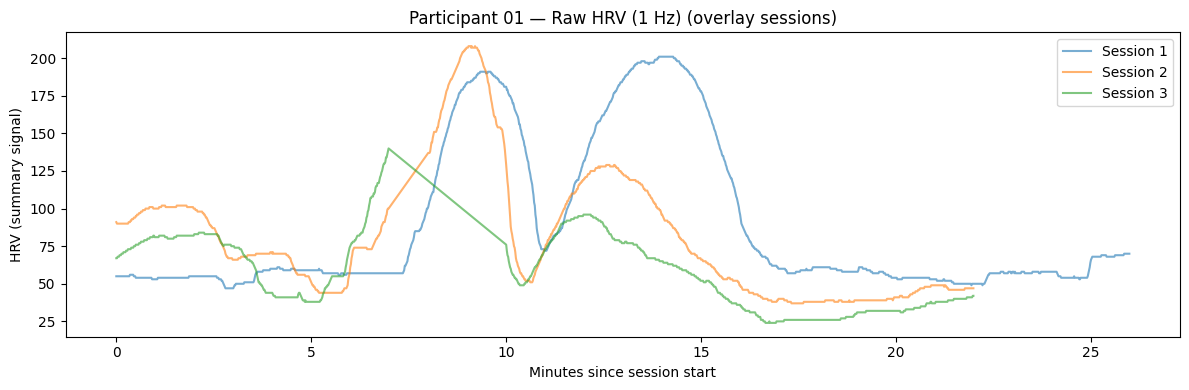

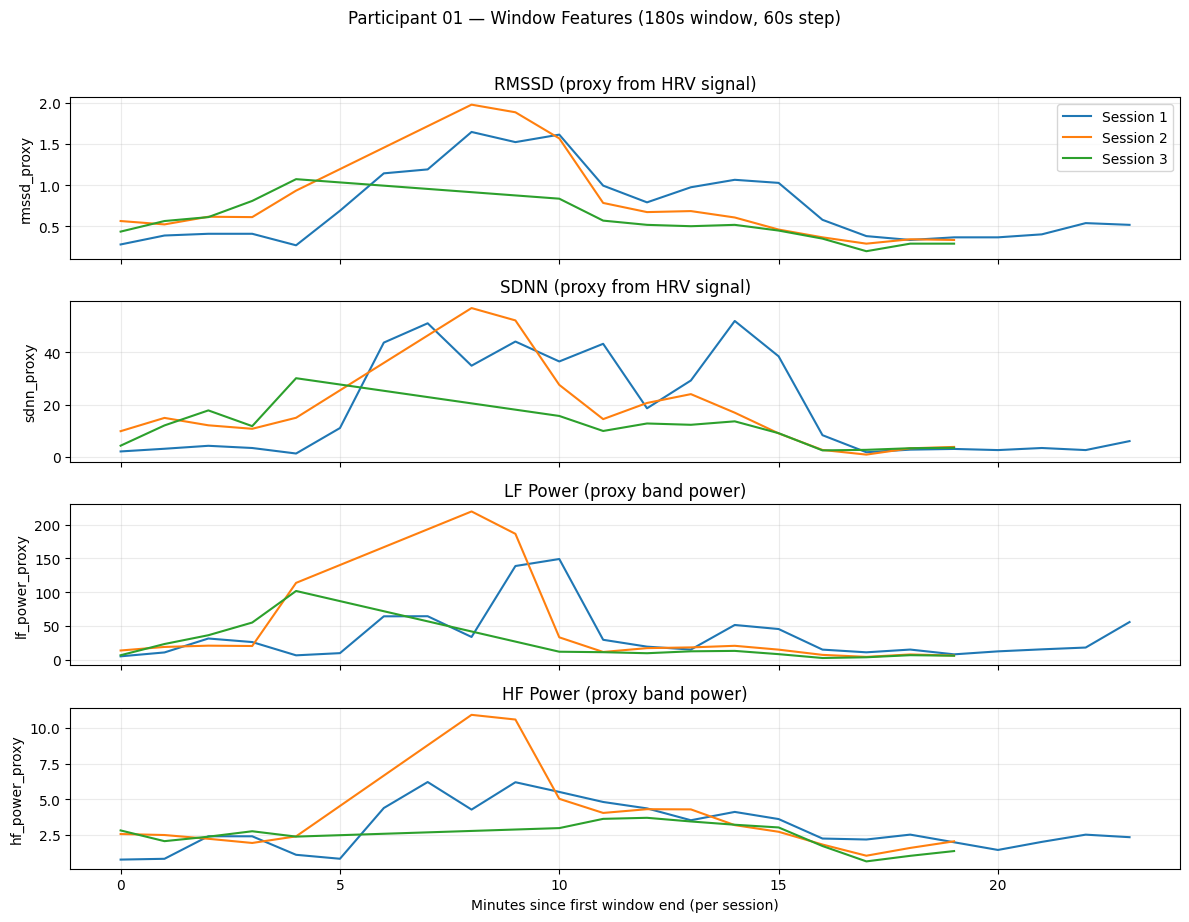

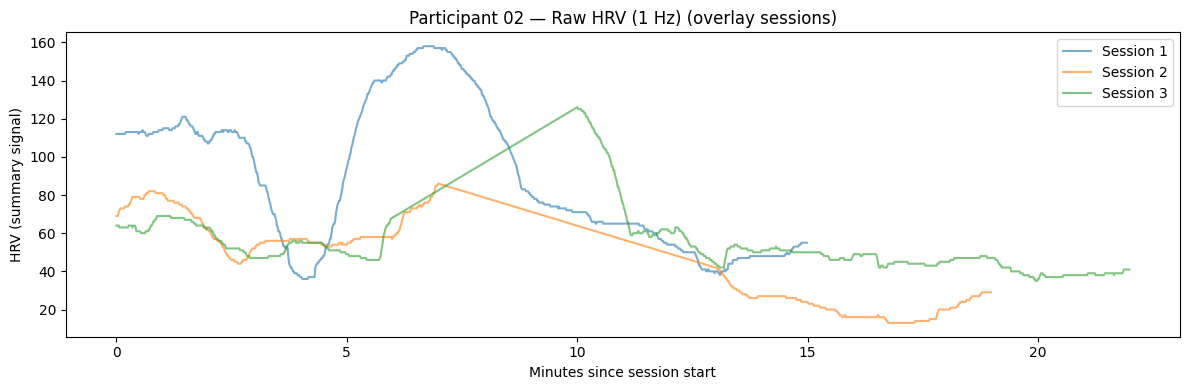

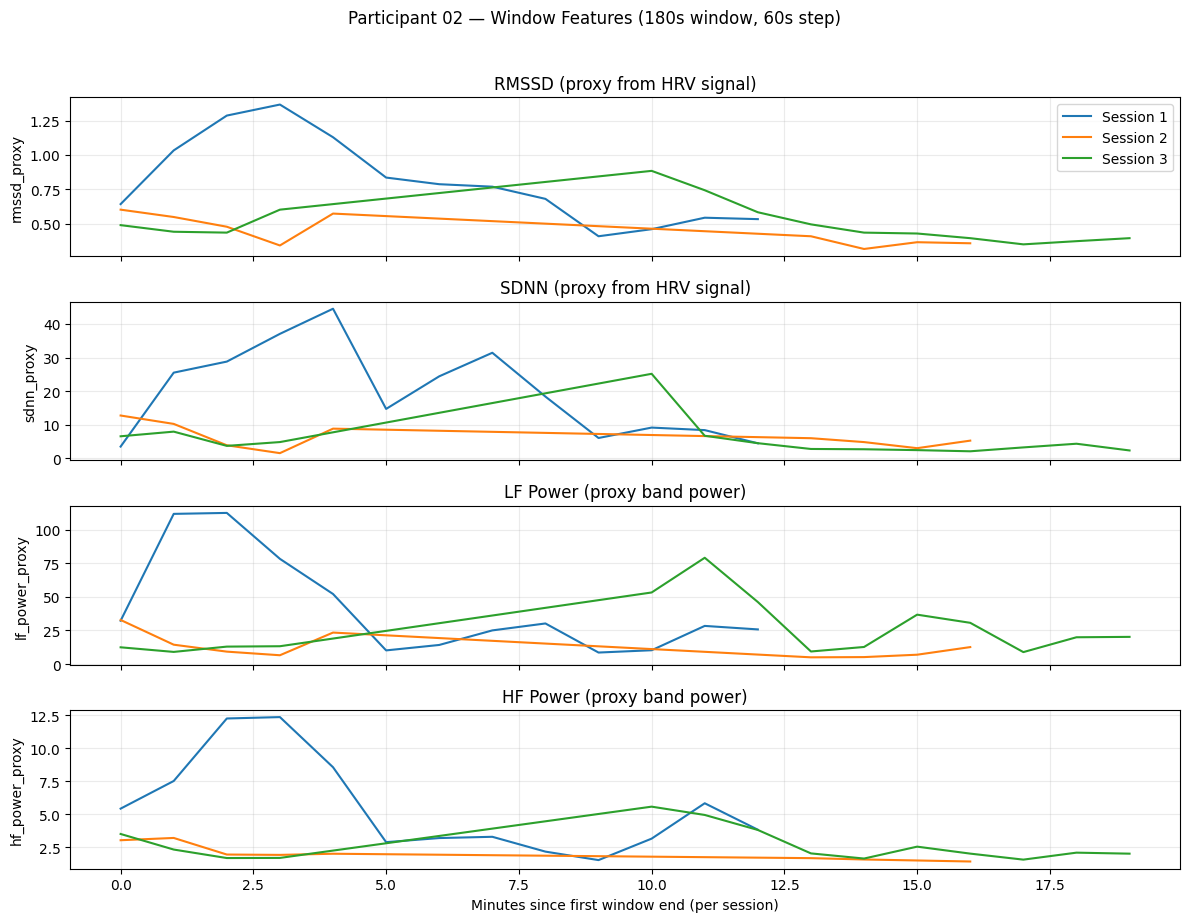

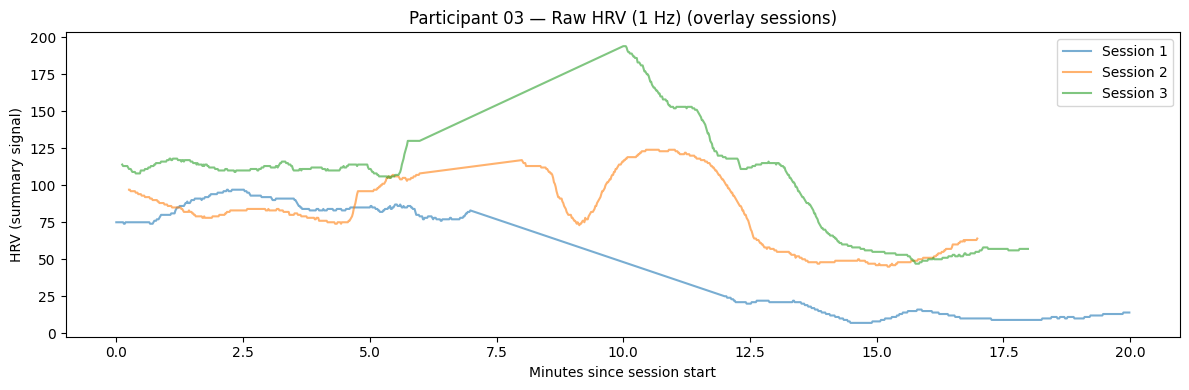

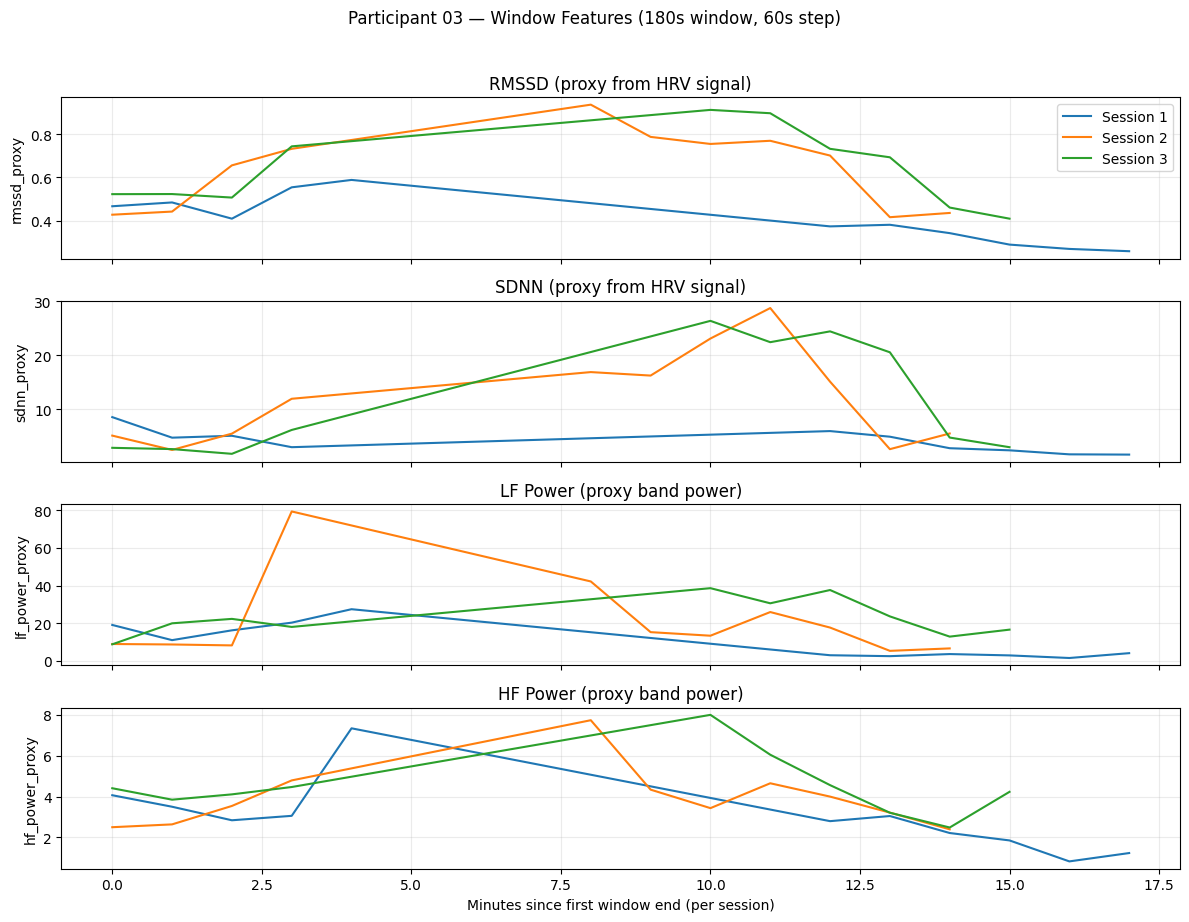

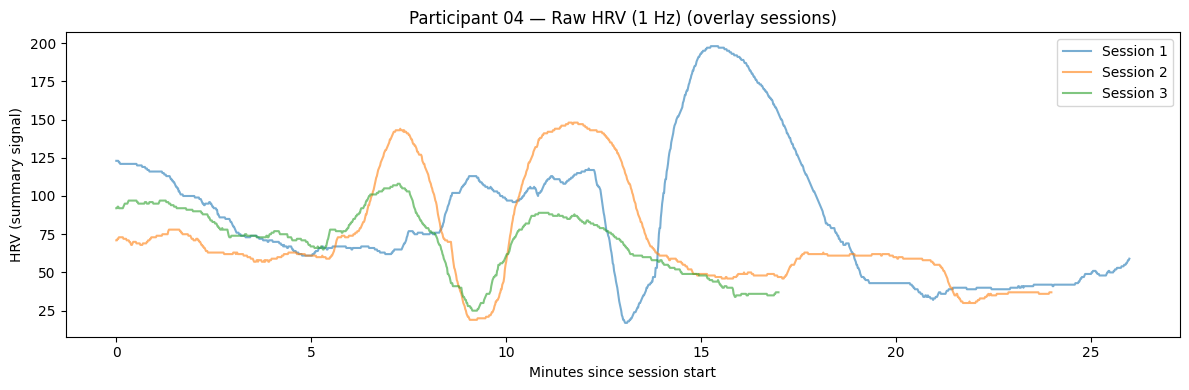

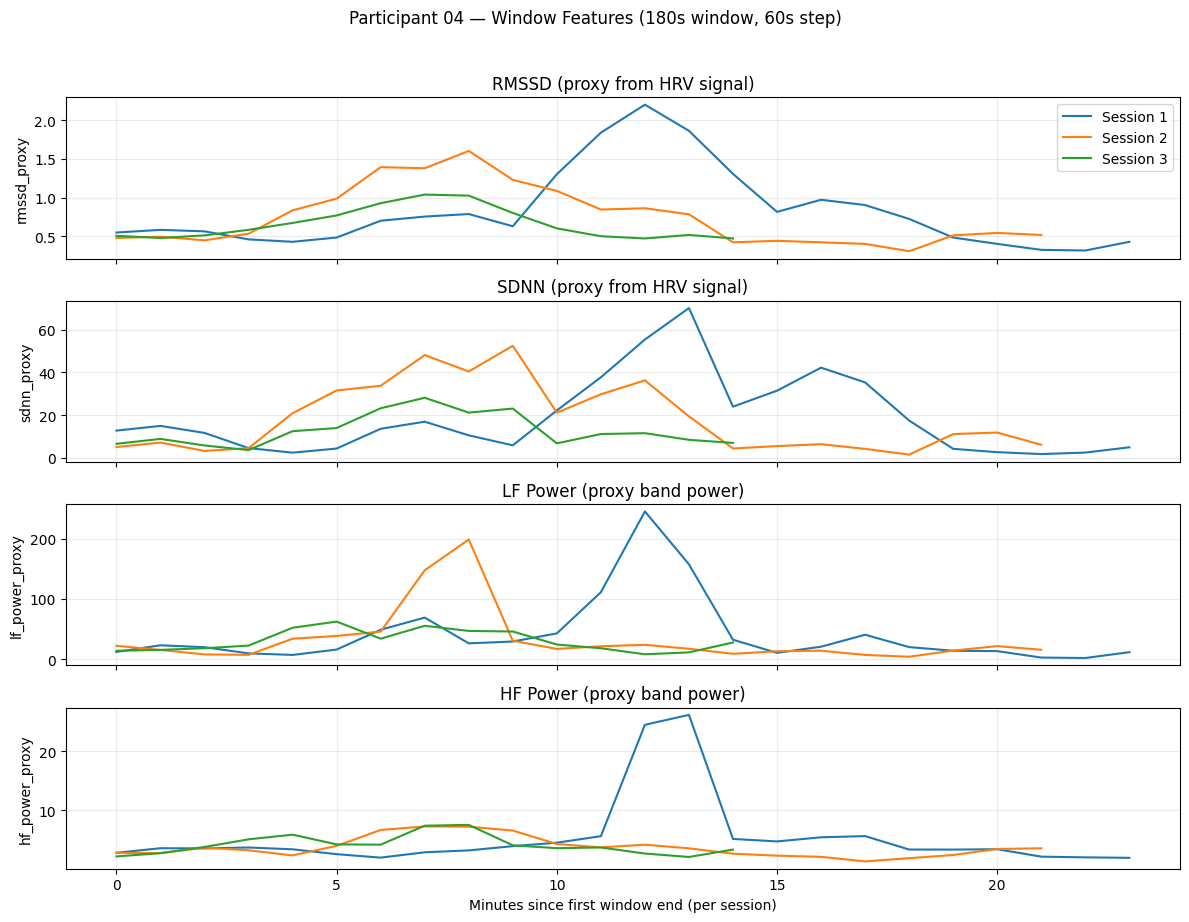

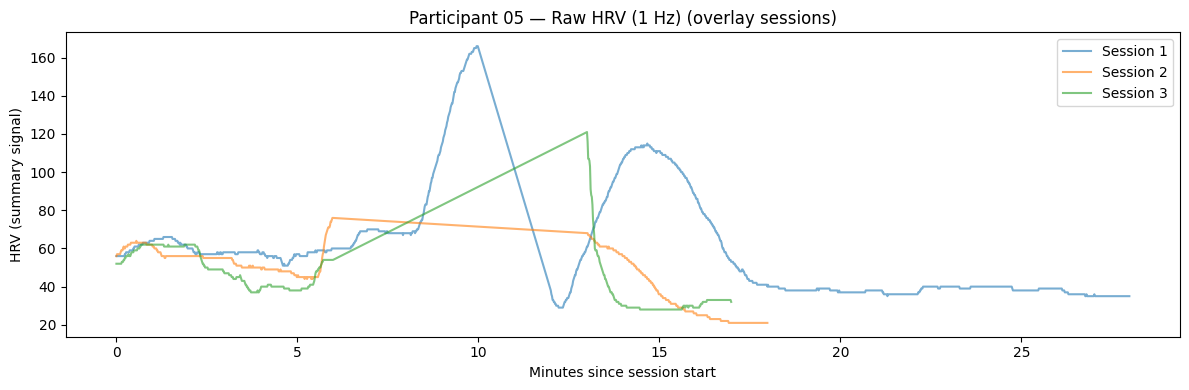

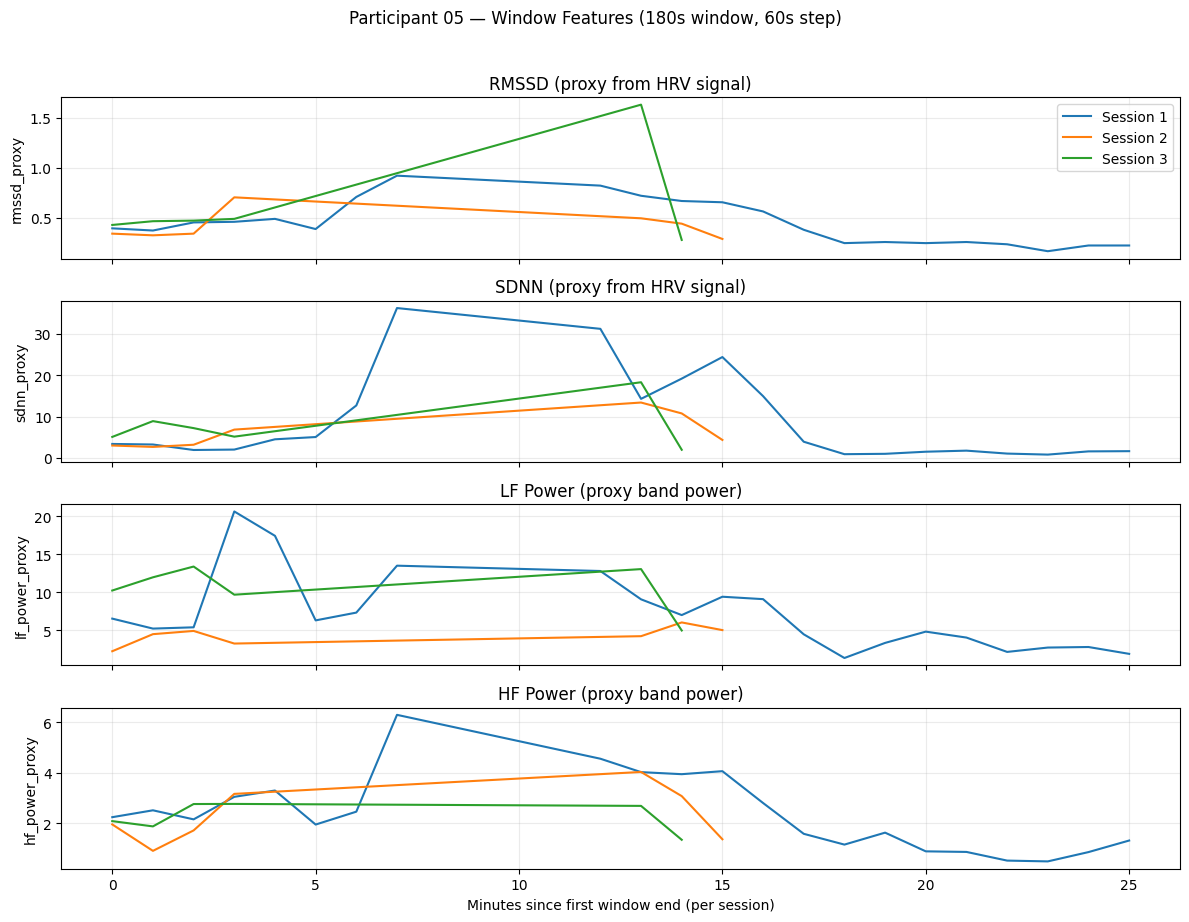

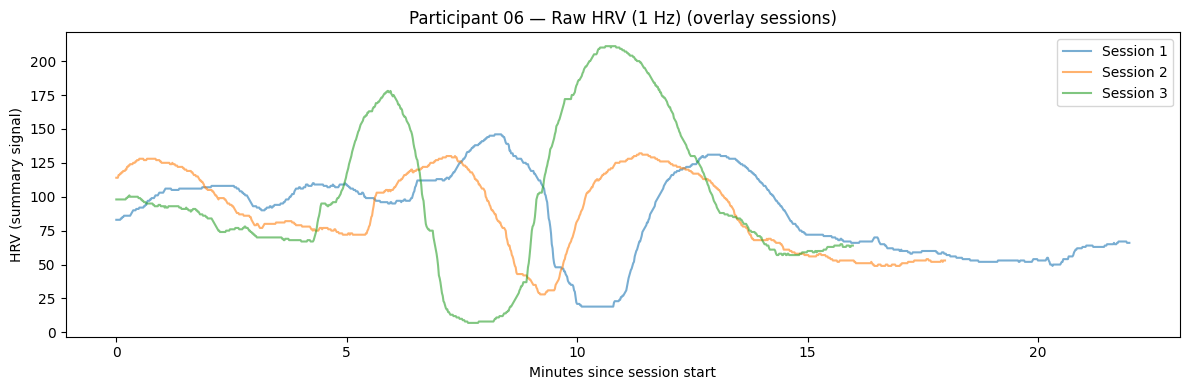

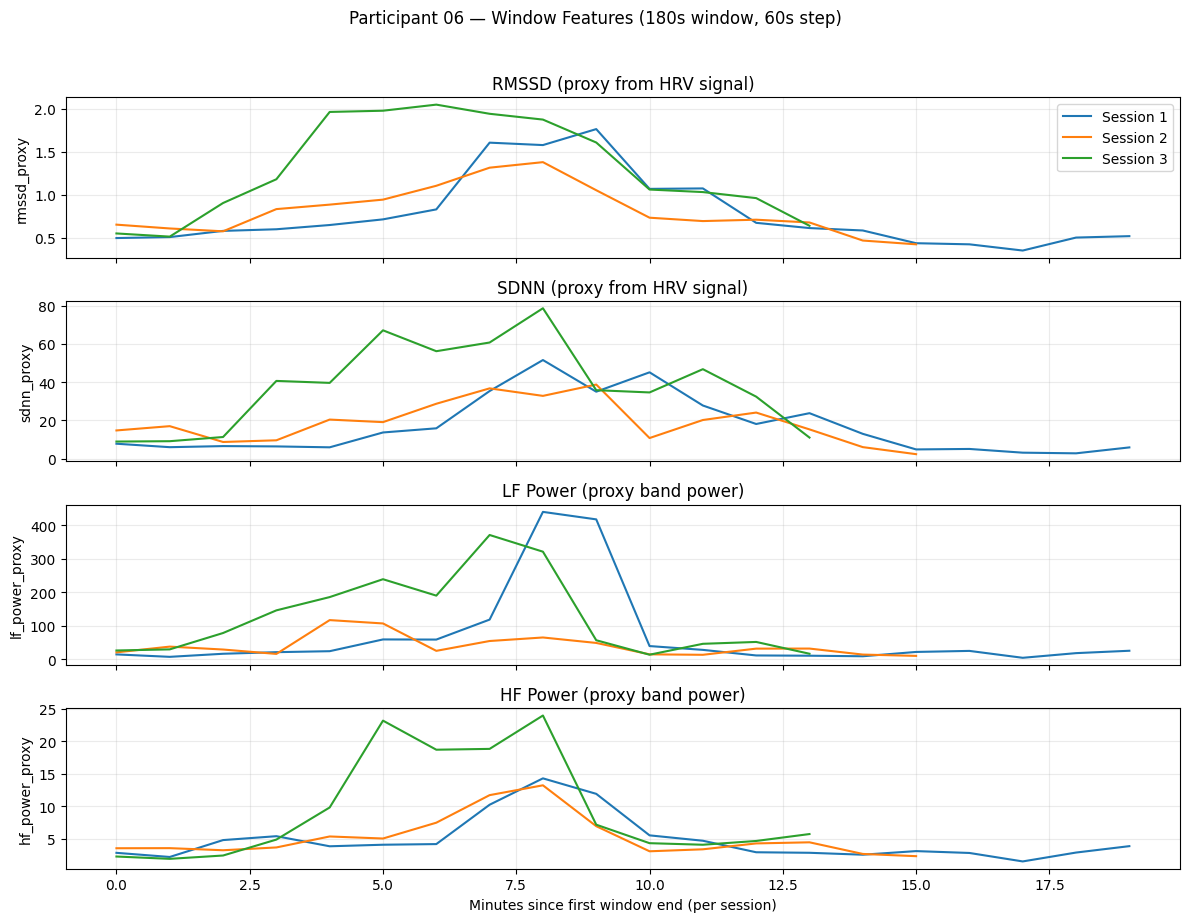

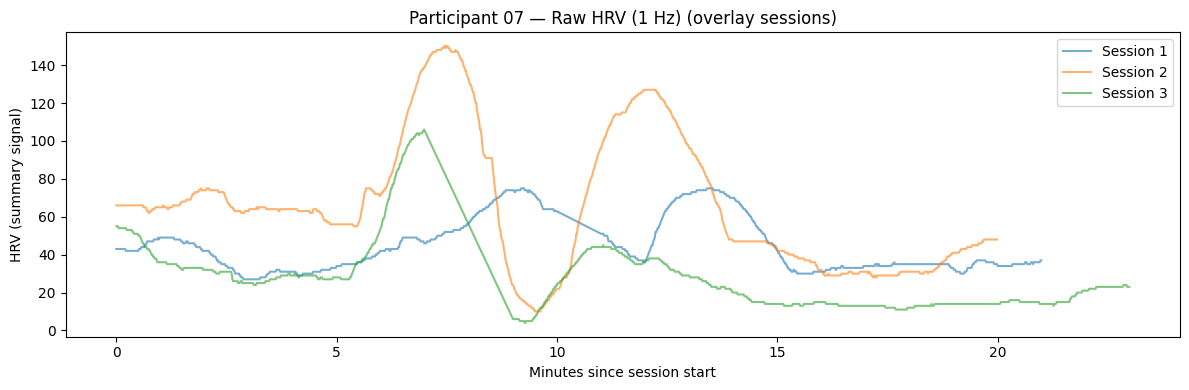

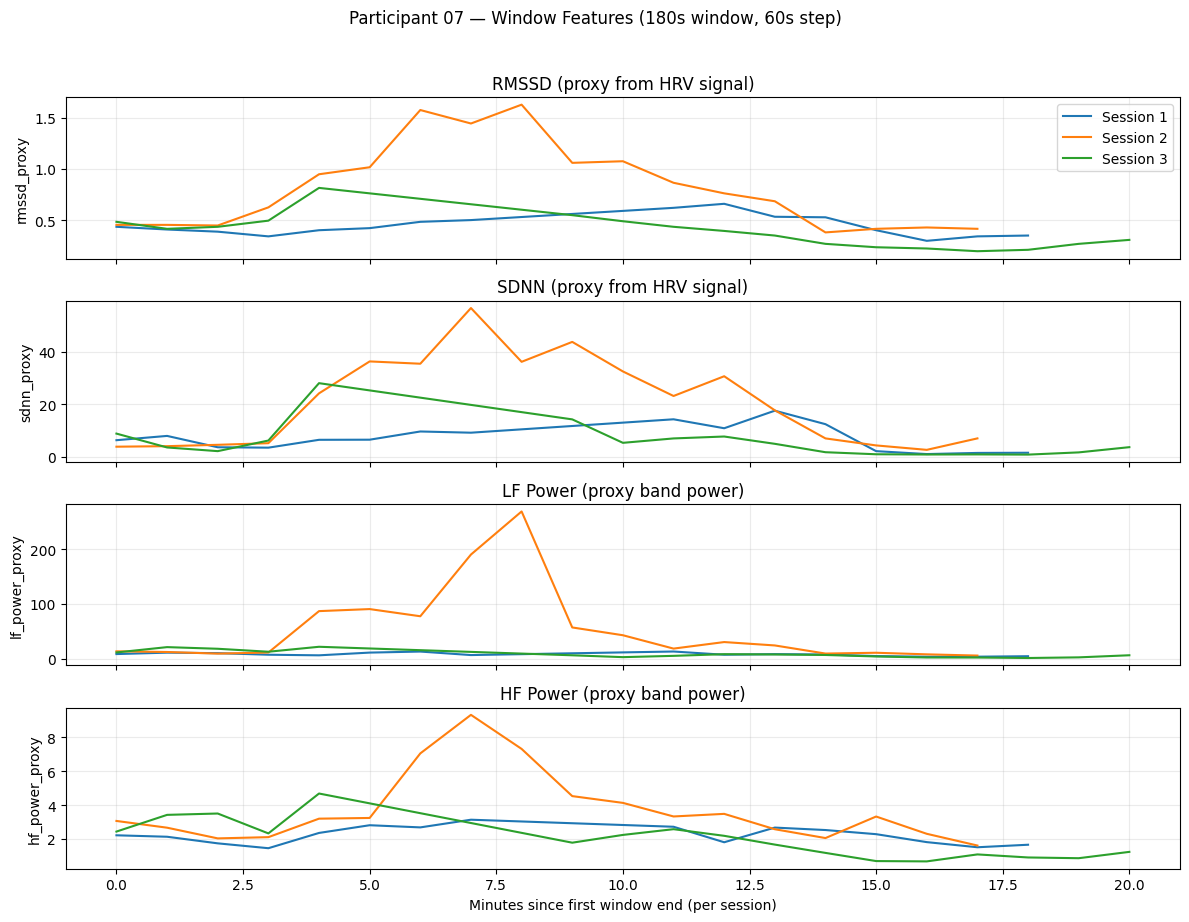

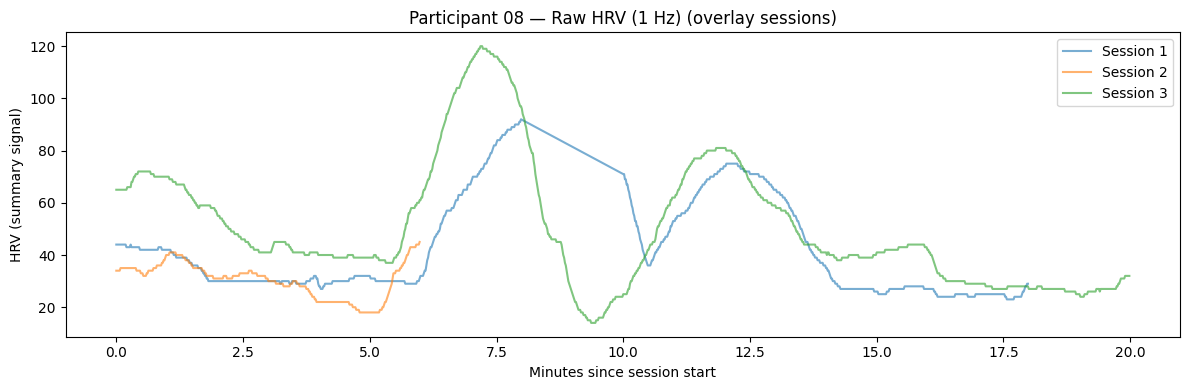

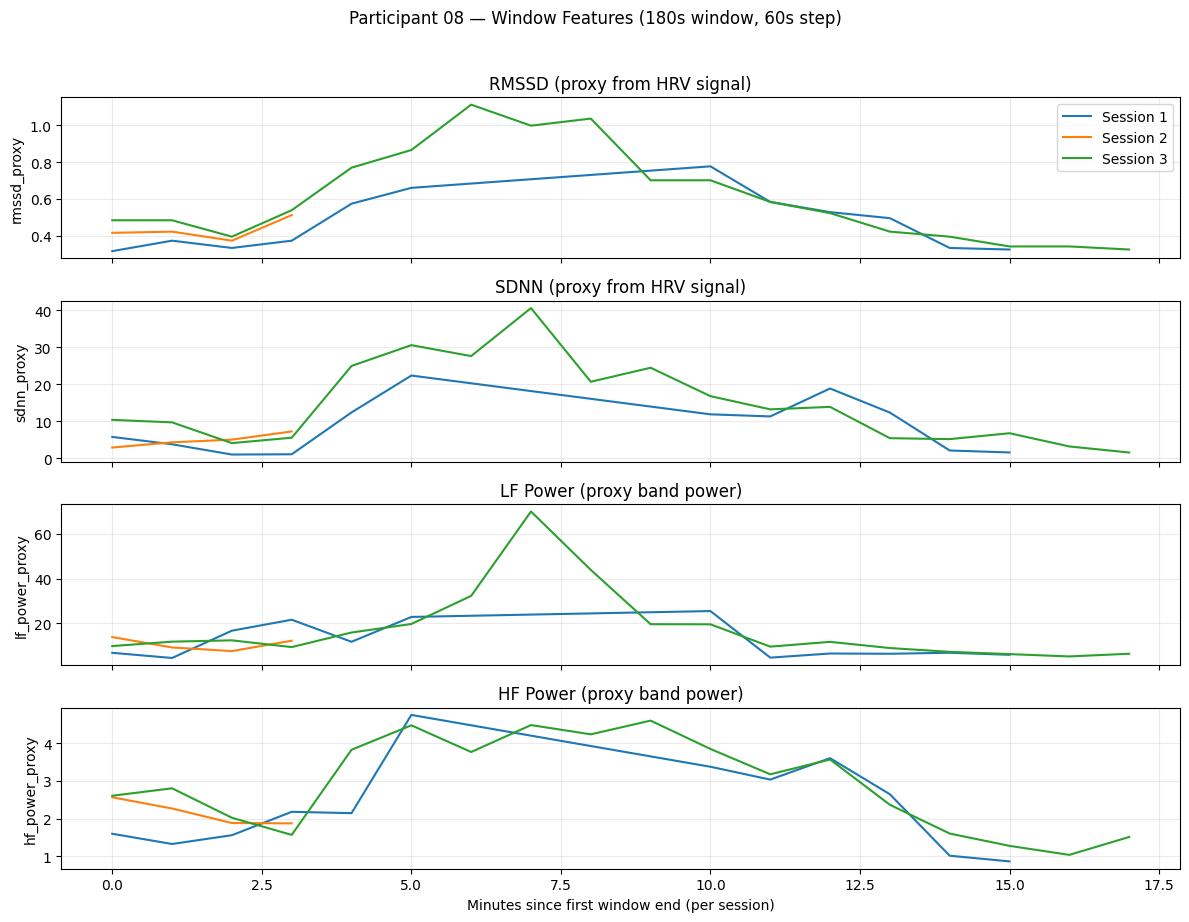

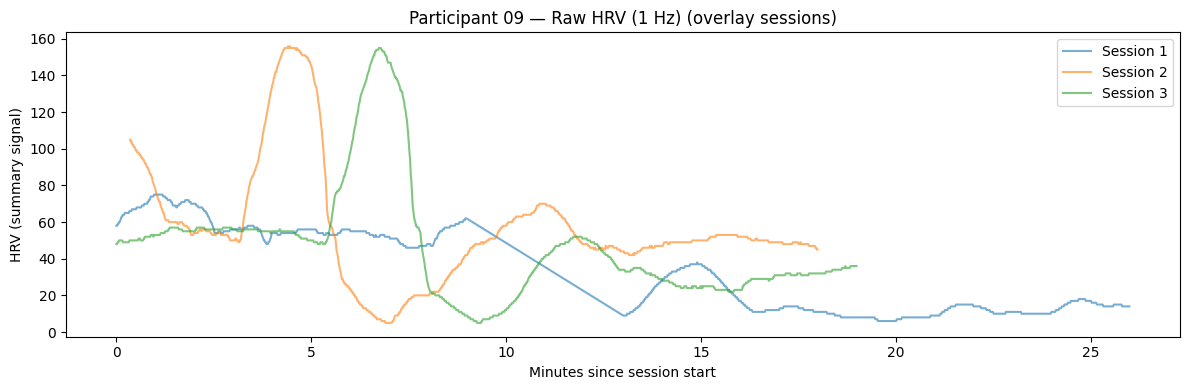

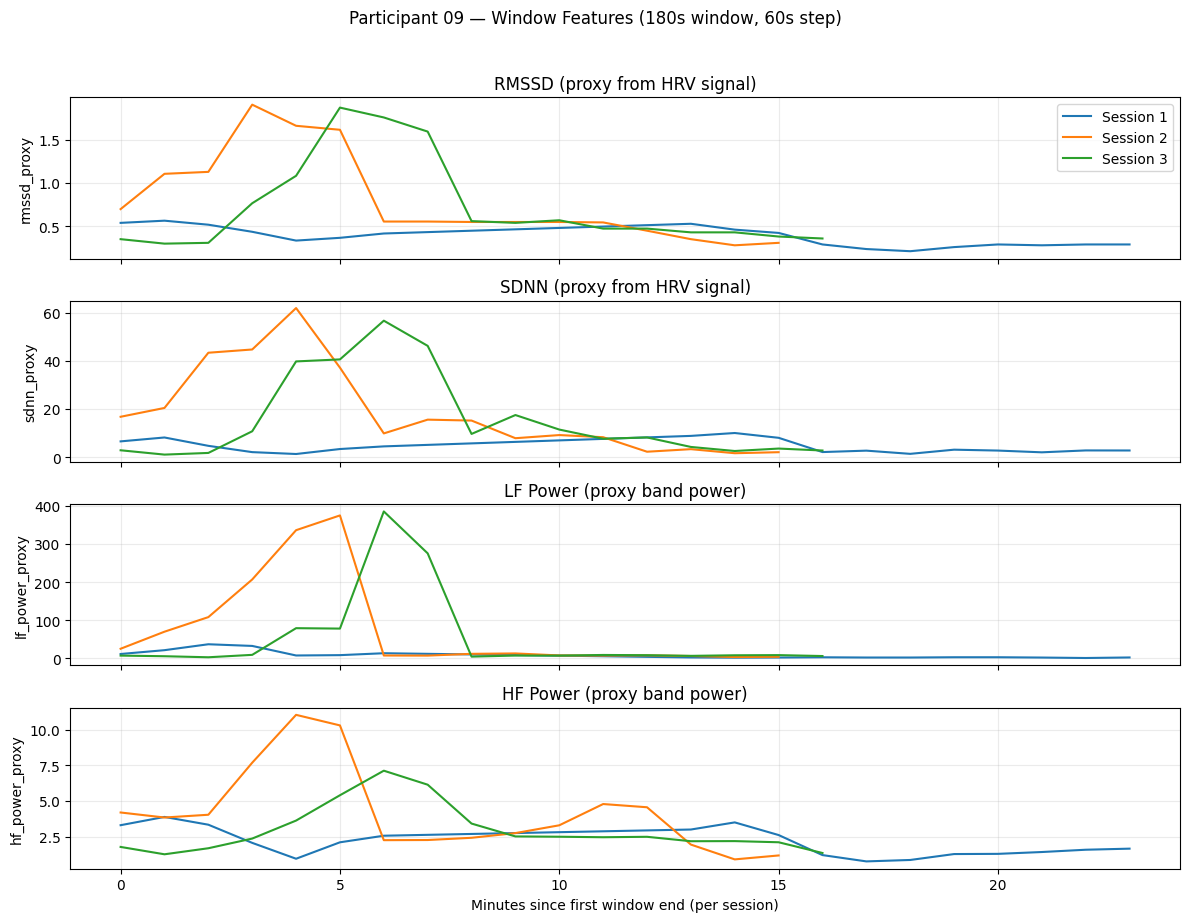

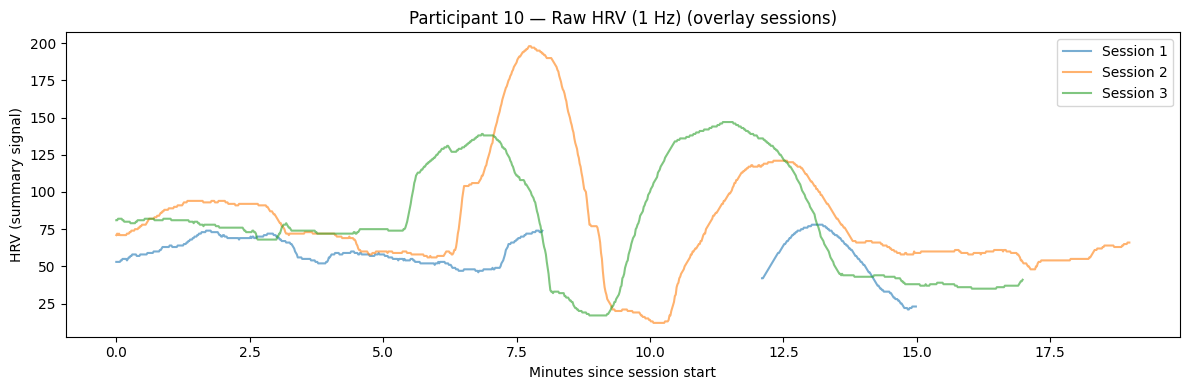

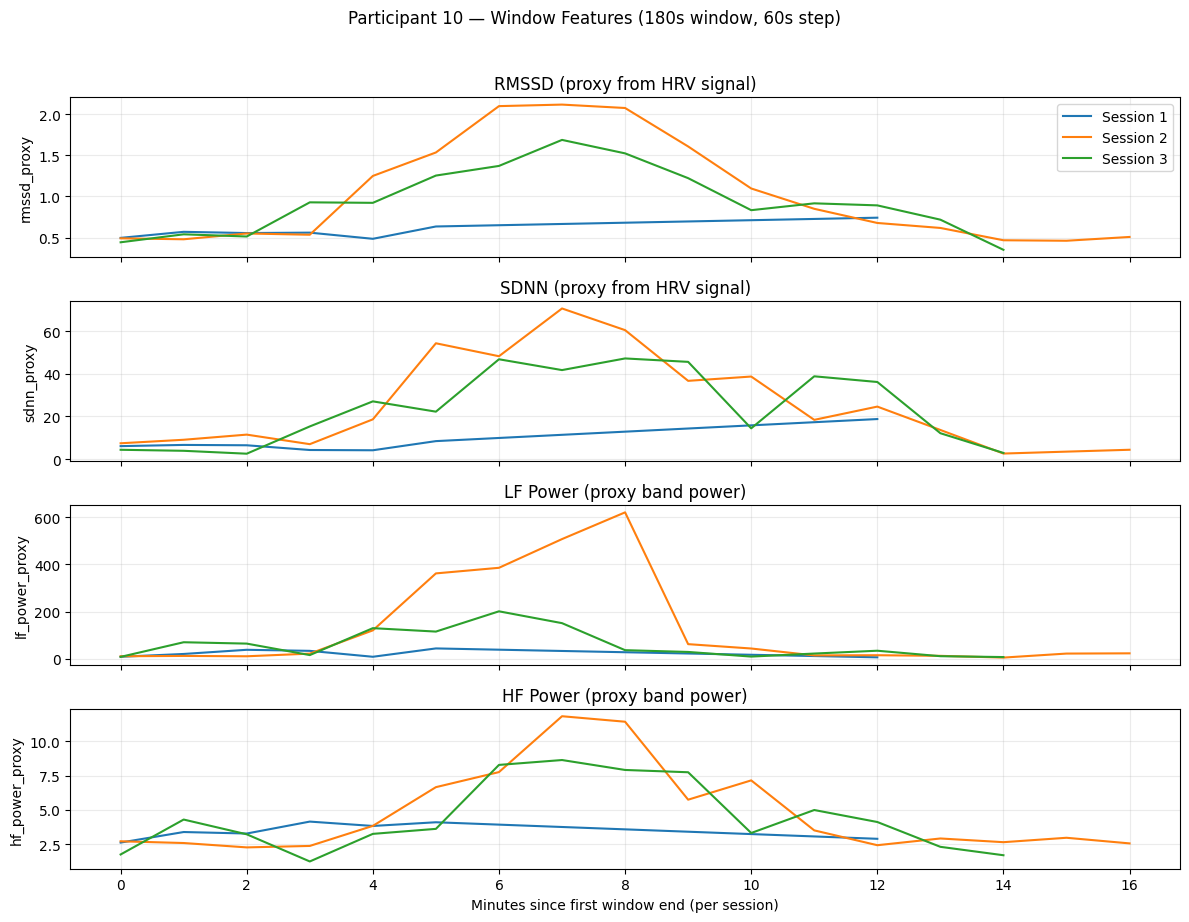

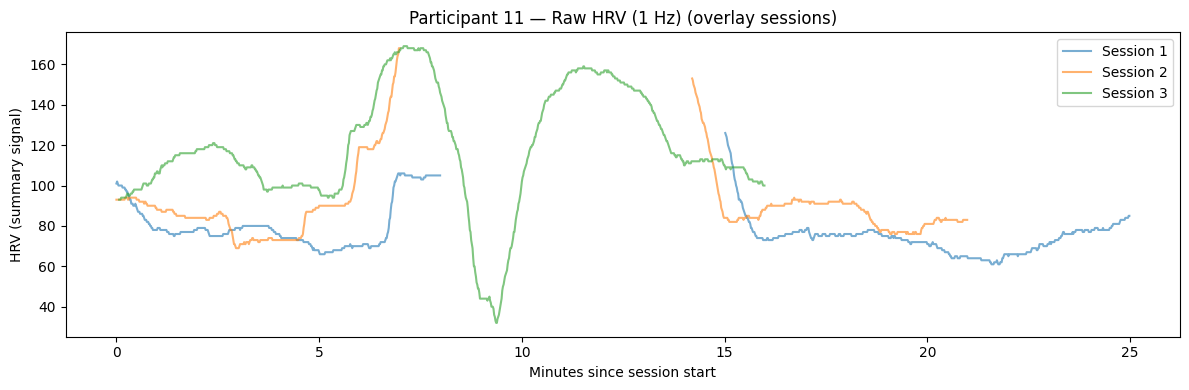

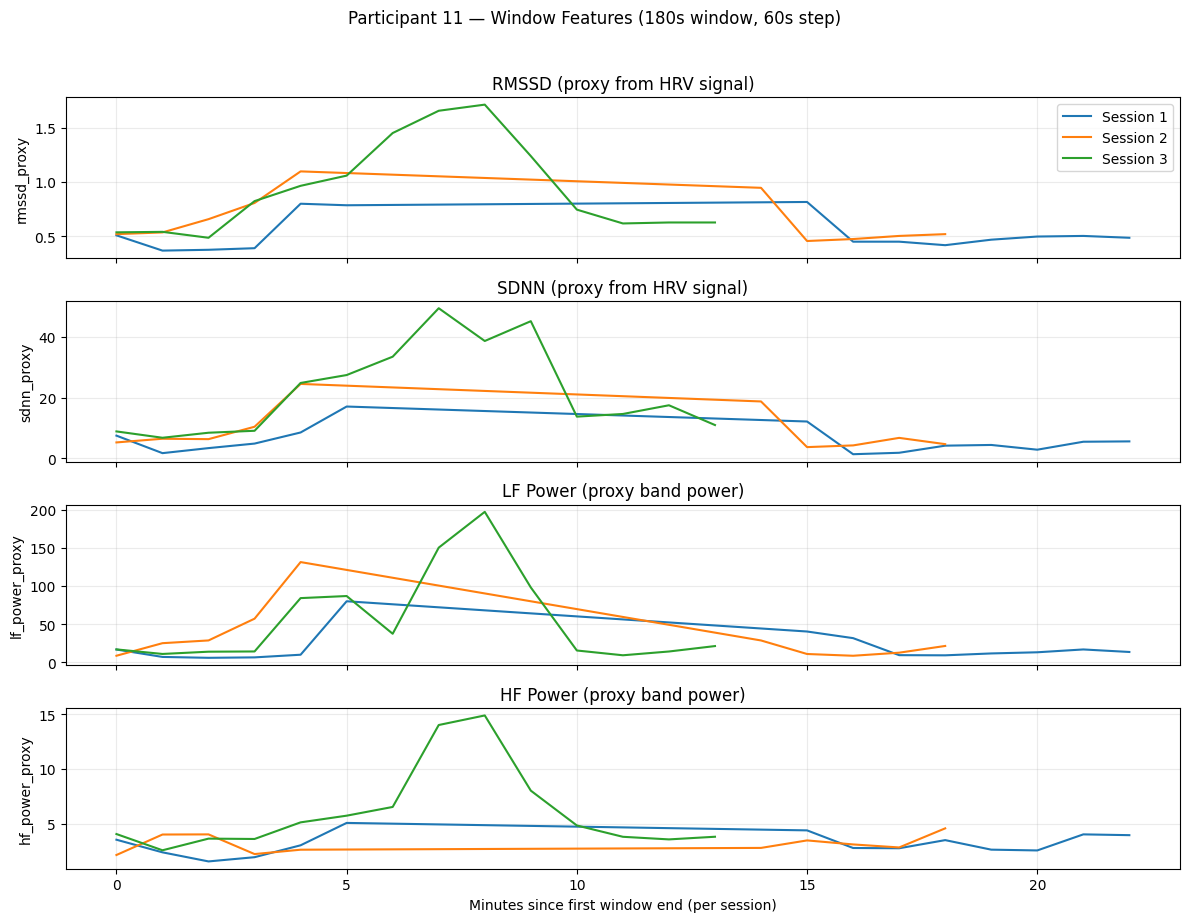

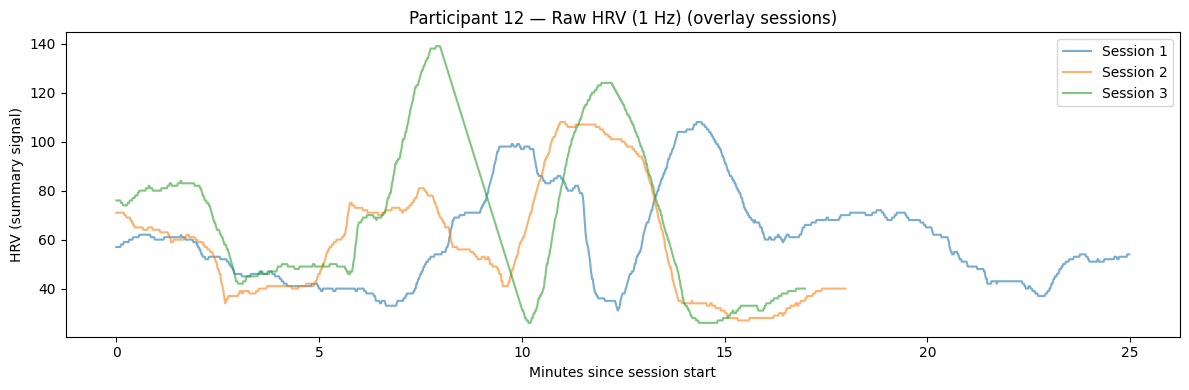

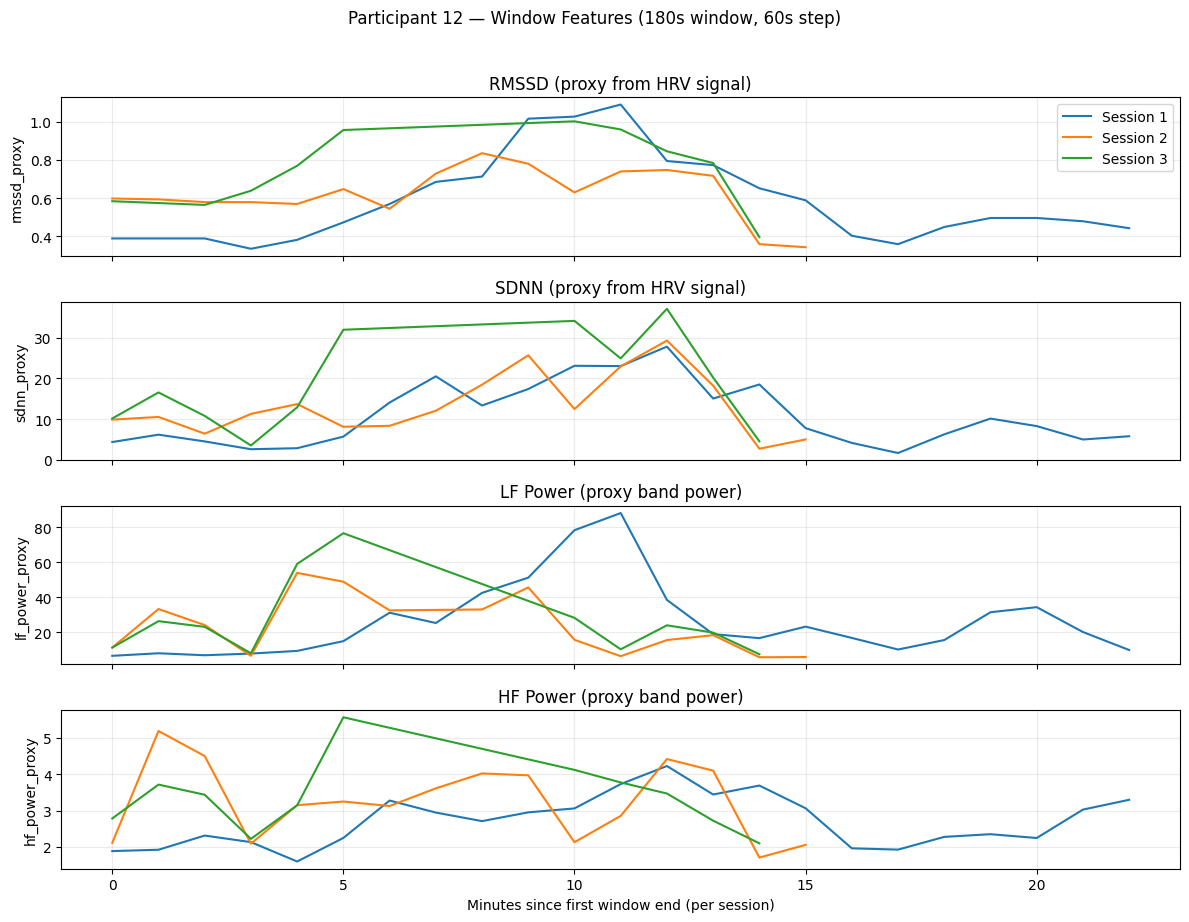

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch


# 1) Compute window-level HRV "proxy" features from your df_windows

def _rmssd_proxy(x: np.ndarray) -> float:
    x = x[np.isfinite(x)]
    if len(x) < 2:
        return np.nan
    d = np.diff(x)
    return float(np.sqrt(np.mean(d * d))) if len(d) else np.nan

def _sdnn_proxy(x: np.ndarray) -> float:
    x = x[np.isfinite(x)]
    return float(np.std(x, ddof=1)) if len(x) >= 2 else np.nan

def _lf_hf_power_proxy(x: np.ndarray, fs: float = 1.0) -> tuple[float, float]:
    x = x[np.isfinite(x)]
    if len(x) < 30:
        return (np.nan, np.nan)

    freqs, psd = welch(x, fs=fs, nperseg=min(len(x), 64))
    lf_band = (freqs >= 0.04) & (freqs < 0.15)
    hf_band = (freqs >= 0.15) & (freqs < 0.40)

    lf_power = float(np.sum(psd[lf_band])) if lf_band.any() else np.nan
    hf_power = float(np.sum(psd[hf_band])) if hf_band.any() else np.nan
    return lf_power, hf_power

def build_window_feature_df(df_windows: pd.DataFrame) -> pd.DataFrame:
    # one row per (participant, session, window_id)
    gcols = ["participant", "session", "window_id"]
    rows = []

    for (pid, sid, wid), w in df_windows.groupby(gcols, sort=False):
        w = w.sort_values("timestamp")
        hrv = w["hrv"].to_numpy(dtype=float)

        rmssd = _rmssd_proxy(hrv)
        sdnn = _sdnn_proxy(hrv)
        lf, hf = _lf_hf_power_proxy(hrv, fs=1.0)

        rows.append({
            "participant": pid,
            "session": sid,
            "window_id": wid,
            "window_start": w["window_start"].iloc[0] if "window_start" in w.columns else w["timestamp"].iloc[0],
            "window_end": w["timestamp"].iloc[-1],

            "rmssd_proxy": rmssd,
            "sdnn_proxy": sdnn,
            "lf_power_proxy": lf,
            "hf_power_proxy": hf,
        })

    feat_df = pd.DataFrame(rows)

    feat_df["t_min"] = feat_df.groupby(["participant","session"])["window_end"].transform(
        lambda s: (s - s.min()).dt.total_seconds()/60.0
    )
    return feat_df

df_win_feats = build_window_feature_df(df_windows)


def plot_participant(pid: int, df_windows: pd.DataFrame, df_win_feats: pd.DataFrame):
    # --- Figure 1: raw HRV ---
    plt.figure(figsize=(12, 4))
    for sid, s in df_windows[df_windows["participant"] == pid].groupby("session", sort=True):
        s = s.sort_values("timestamp")
        # minutes from start of this session
        t_min = (s["timestamp"] - s["timestamp"].min()).dt.total_seconds() / 60.0
        plt.plot(t_min, s["hrv"], label=f"Session {sid}", alpha=0.6)

    plt.title(f"Participant {pid:02d} — Raw HRV (1 Hz) (overlay sessions)")
    plt.xlabel("Minutes since session start")
    plt.ylabel("HRV (summary signal)")
    plt.legend()
    plt.tight_layout()
    plt.show()


    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    metrics = [
        ("rmssd_proxy", "RMSSD (proxy from HRV signal)"),
        ("sdnn_proxy", "SDNN (proxy from HRV signal)"),
        ("lf_power_proxy", "LF Power (proxy band power)"),
        ("hf_power_proxy", "HF Power (proxy band power)"),
    ]

    sub = df_win_feats[df_win_feats["participant"] == pid].copy()
    for ax, (col, title) in zip(axes, metrics):
        for sid, s in sub.groupby("session", sort=True):
            s = s.sort_values("t_min")
            ax.plot(s["t_min"], s[col], label=f"Session {sid}")
        ax.set_title(title)
        ax.set_ylabel(col)
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel("Minutes since first window end (per session)")
    axes[0].legend()
    fig.suptitle(f"Participant {pid:02d} — Window Features (180s window, 60s step)", y=1.02)
    plt.tight_layout()
    plt.show()

# Run for all participants
for pid in sorted(df_windows["participant"].unique()):
    plot_participant(pid, df_windows, df_win_feats)

(533, 10)
   participant  session  window_id              window_start  \
0            1        1          0 2021-08-19 10:53:43+00:00   
1            1        1          1 2021-08-19 10:54:43+00:00   
2            1        1          2 2021-08-19 10:55:43+00:00   
3            1        1          3 2021-08-19 10:56:43+00:00   
4            1        1          4 2021-08-19 10:57:43+00:00   

                 window_end  temp_rmssd  temp_sdnn  temp_lf_power  \
0 2021-08-19 10:56:42+00:00    0.018656   0.037049       0.003452   
1 2021-08-19 10:57:42+00:00    0.019231   0.018781       0.004242   
2 2021-08-19 10:58:42+00:00    0.019027   0.034721       0.004433   
3 2021-08-19 10:59:42+00:00    0.018746   0.032068       0.002930   
4 2021-08-19 11:00:42+00:00    0.018460   0.017877       0.002154   

   temp_hf_power  t_min  
0       0.004715    0.0  
1       0.006922    1.0  
2       0.006284    2.0  
3       0.004741    3.0  
4       0.006112    4.0  


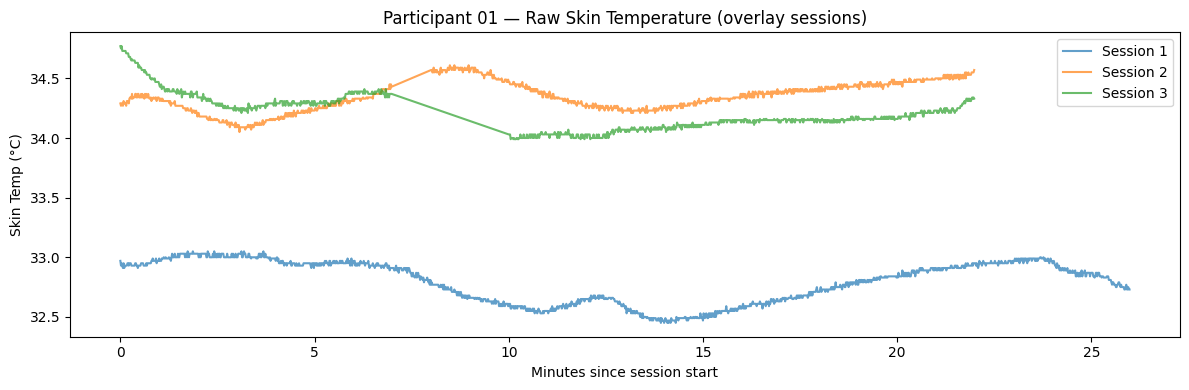

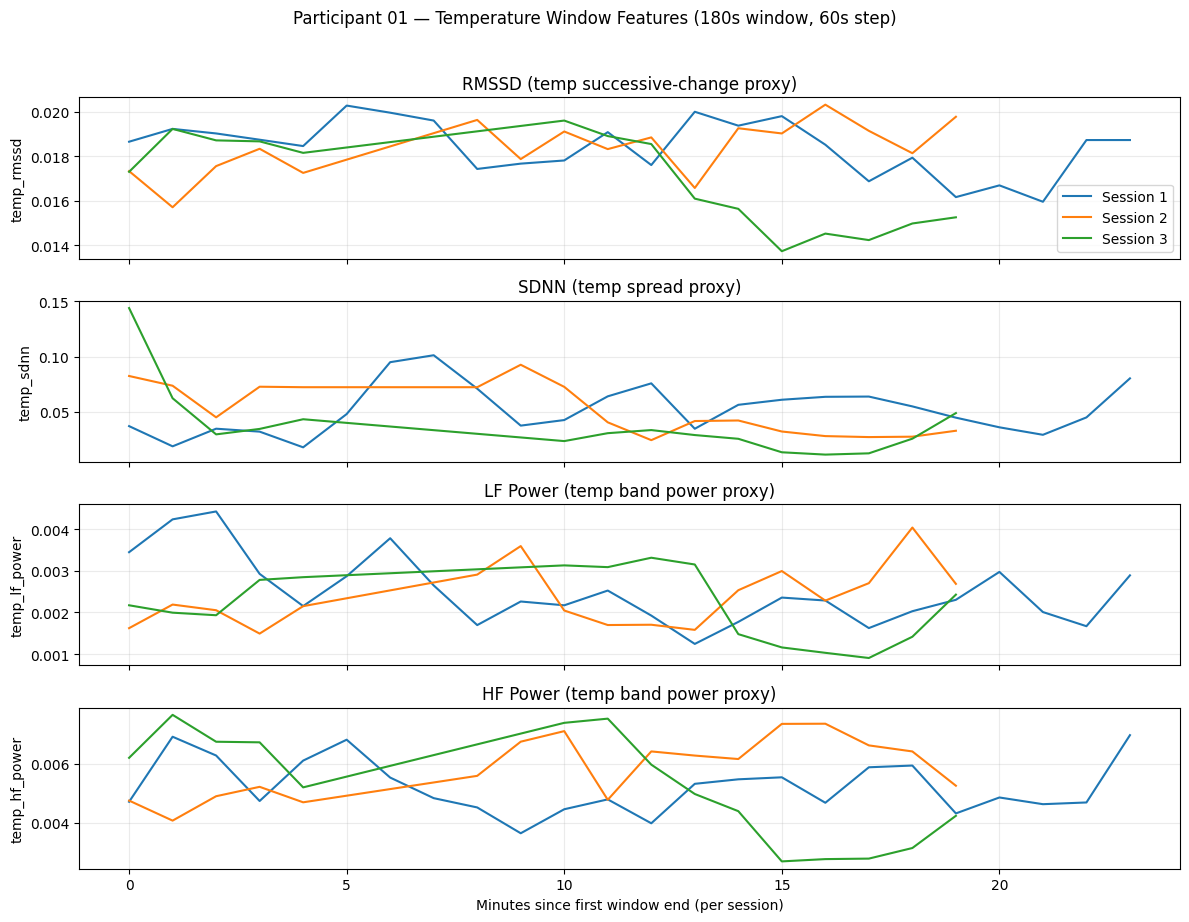

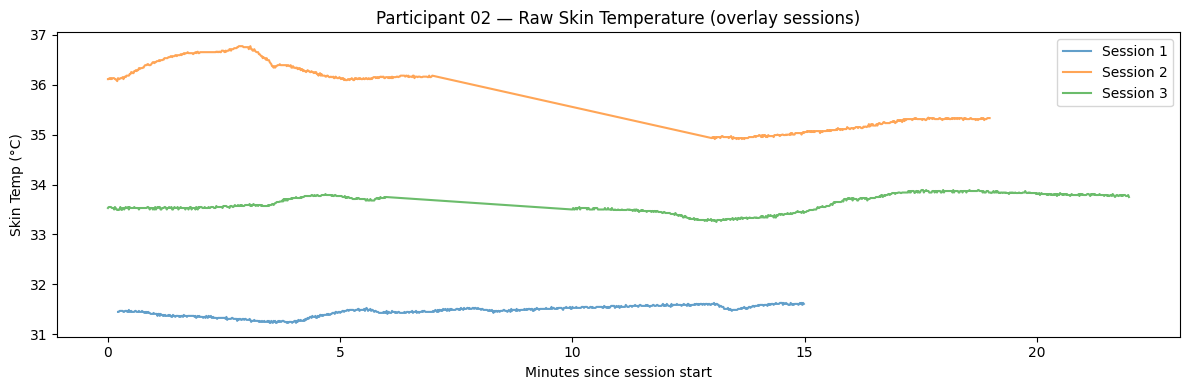

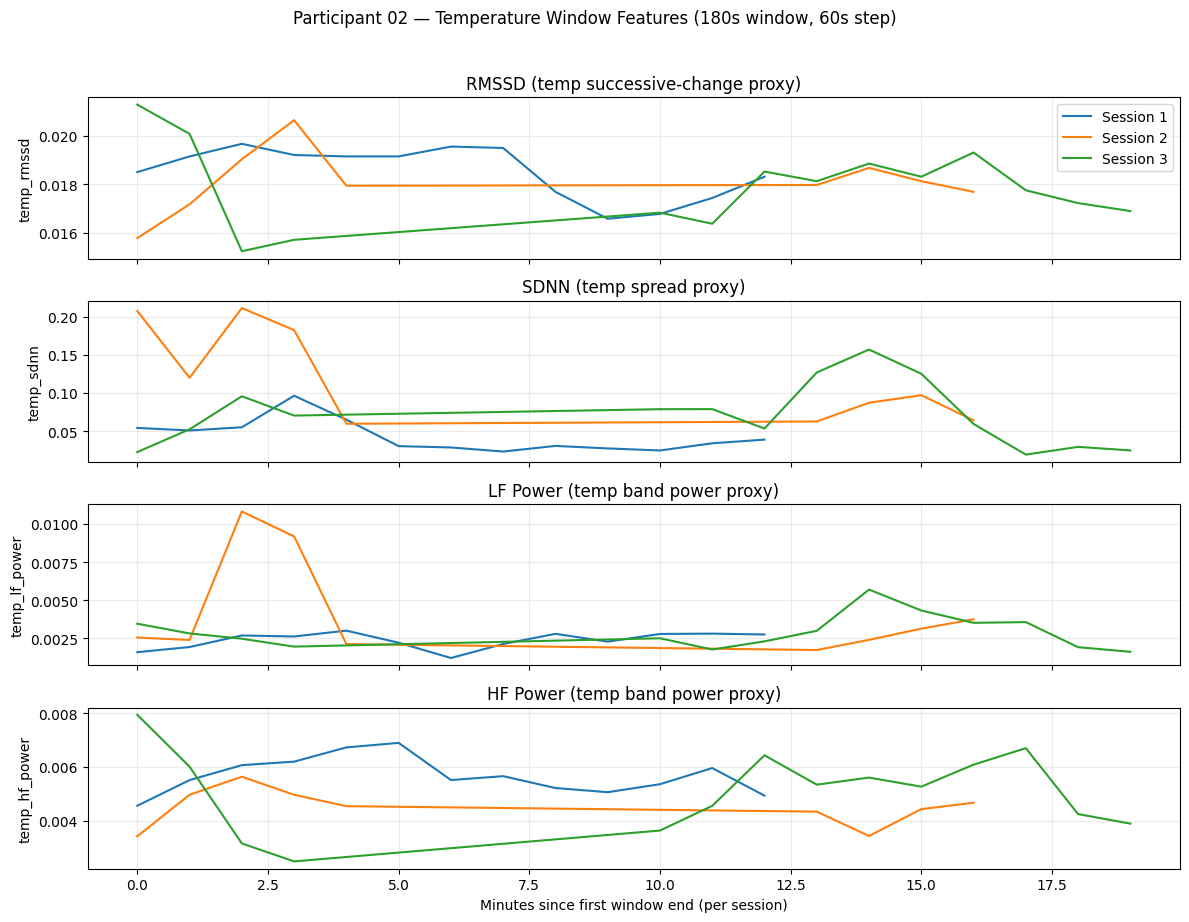

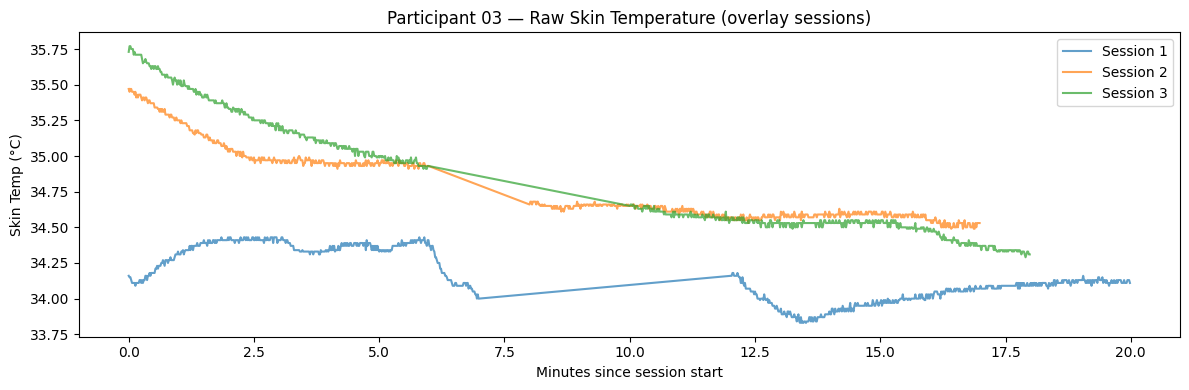

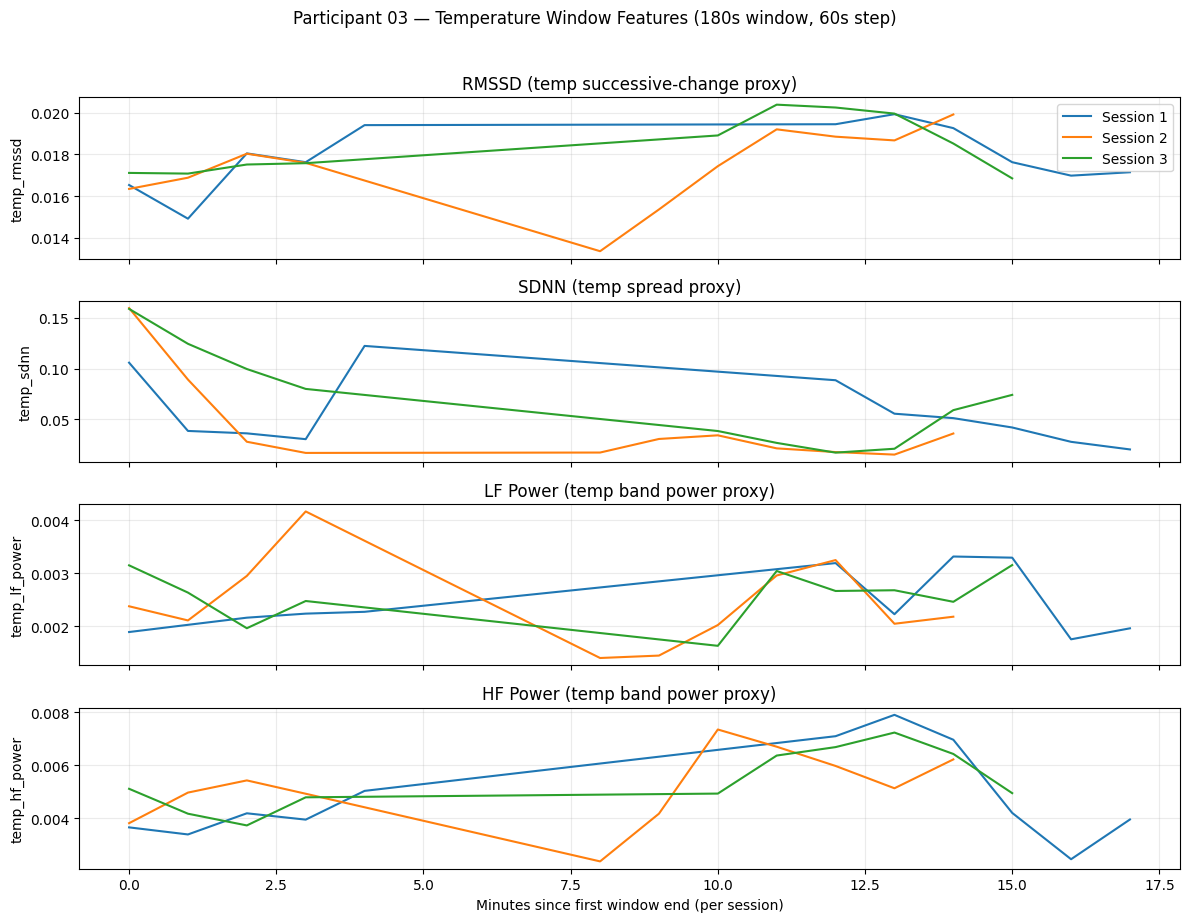

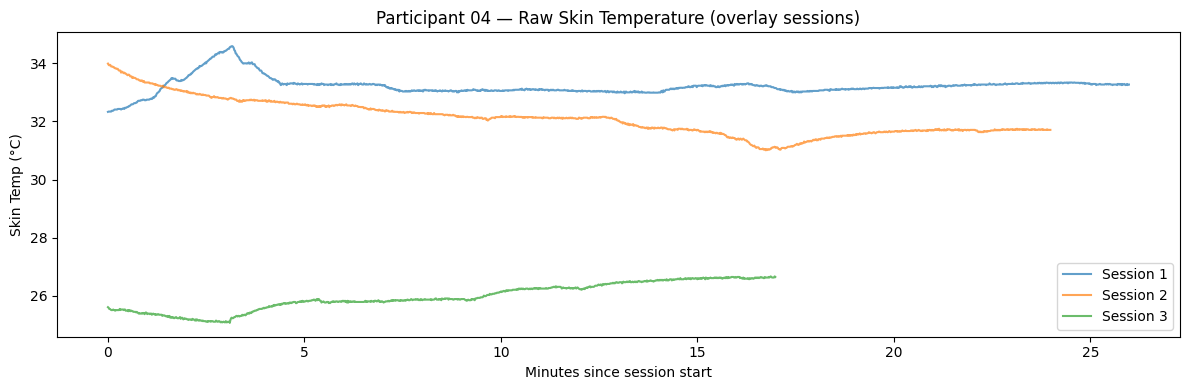

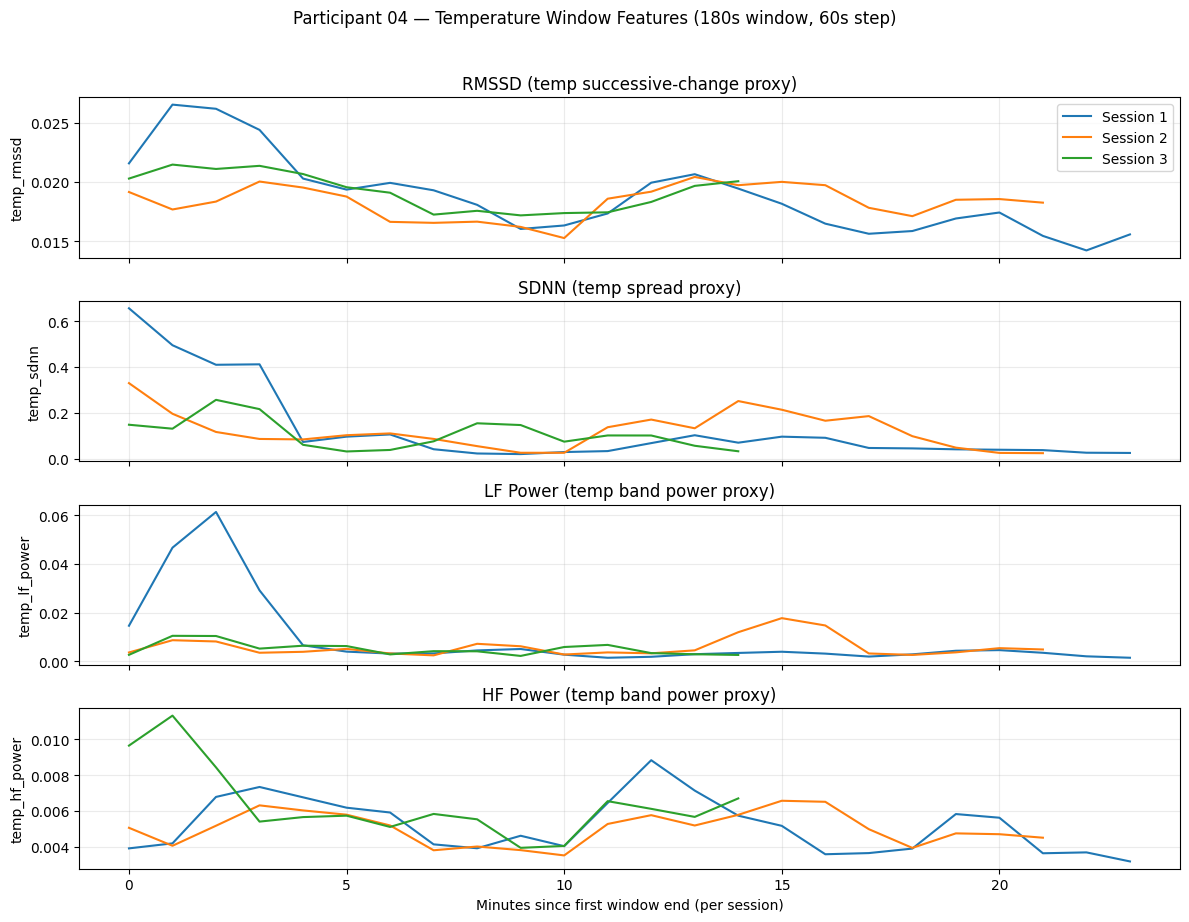

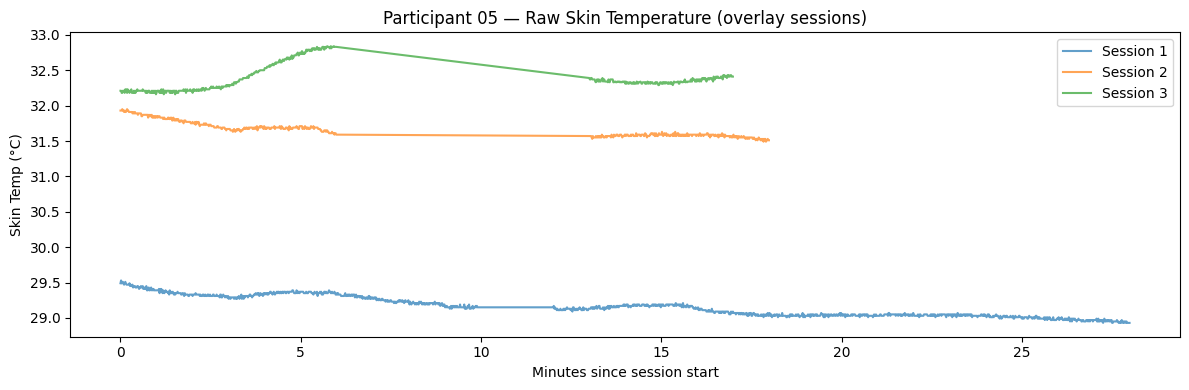

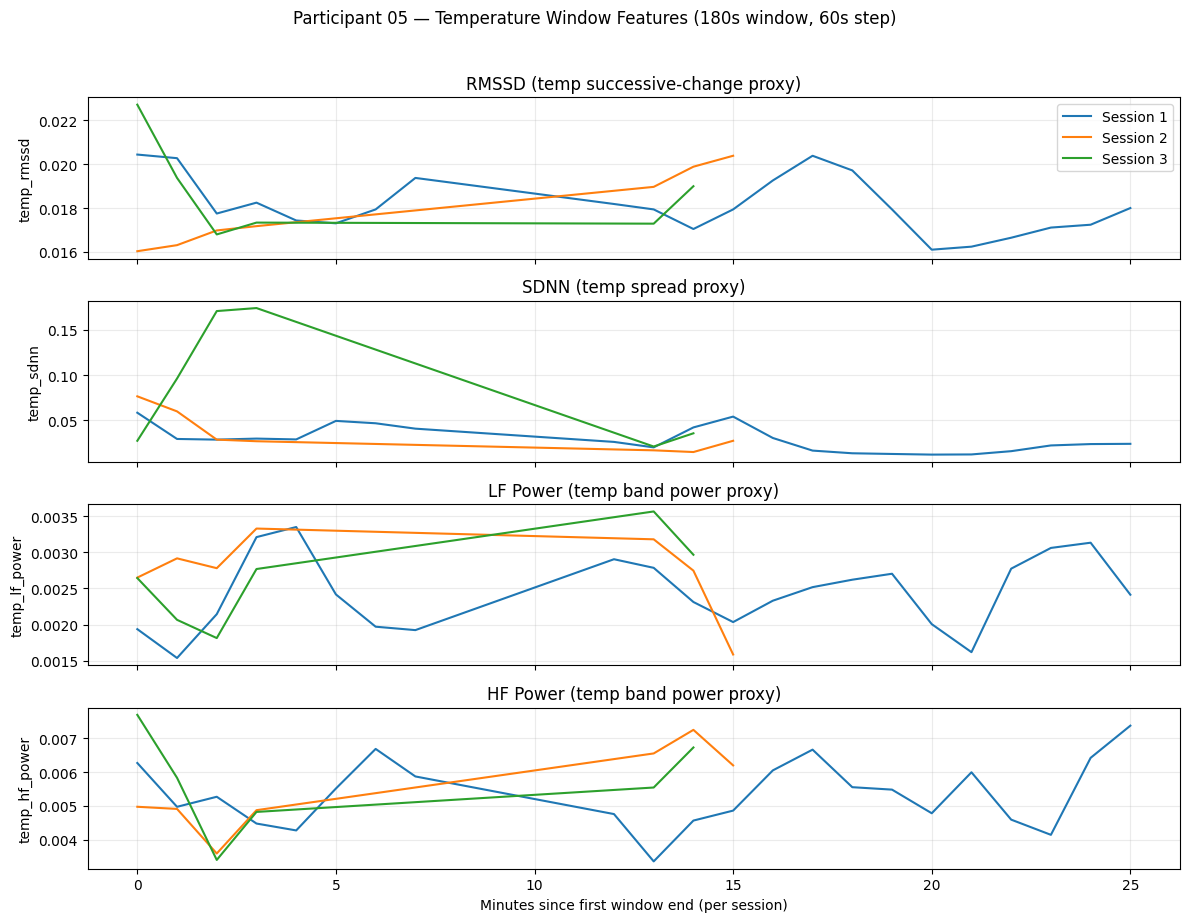

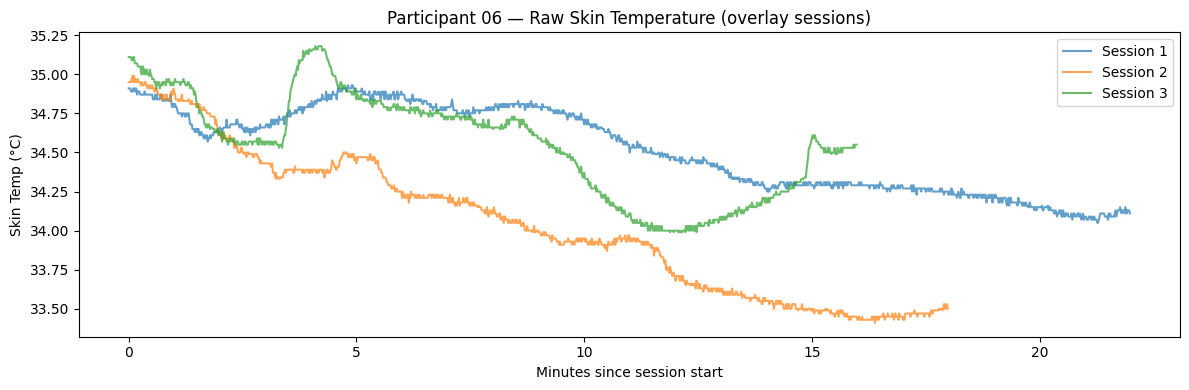

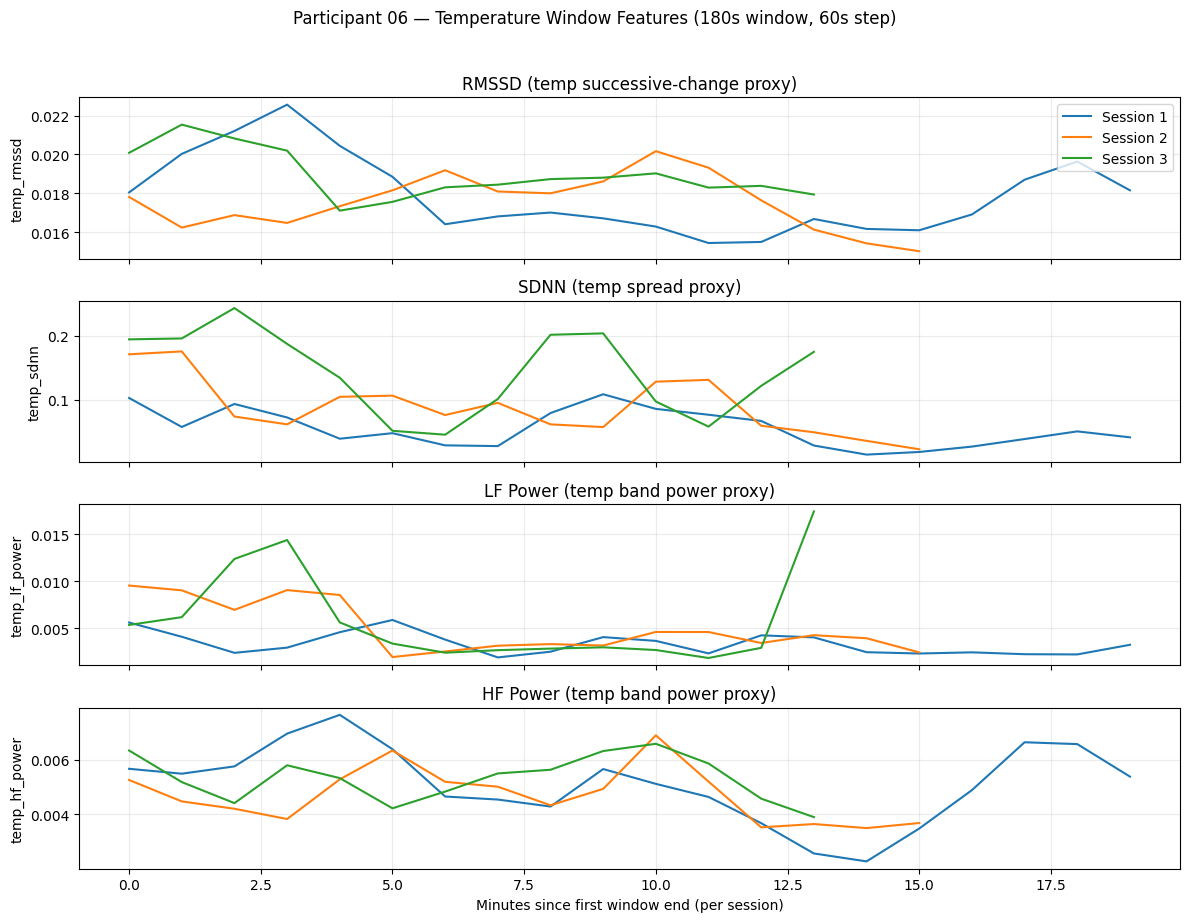

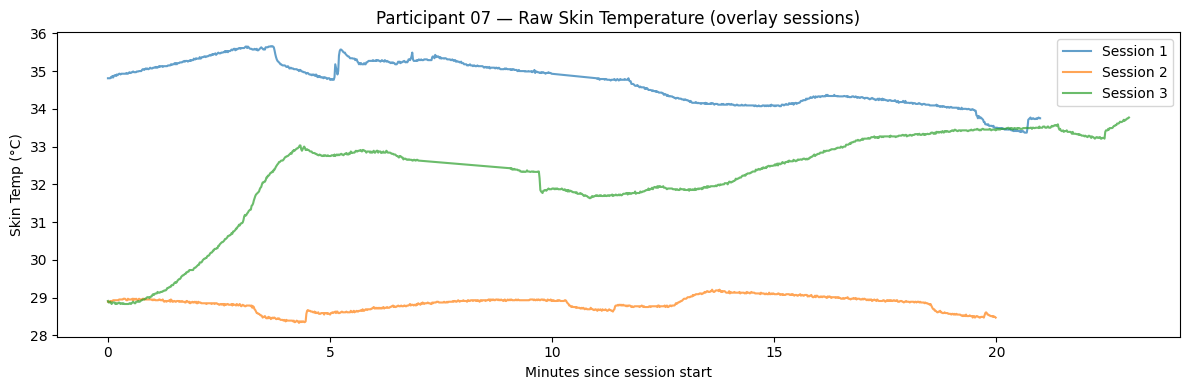

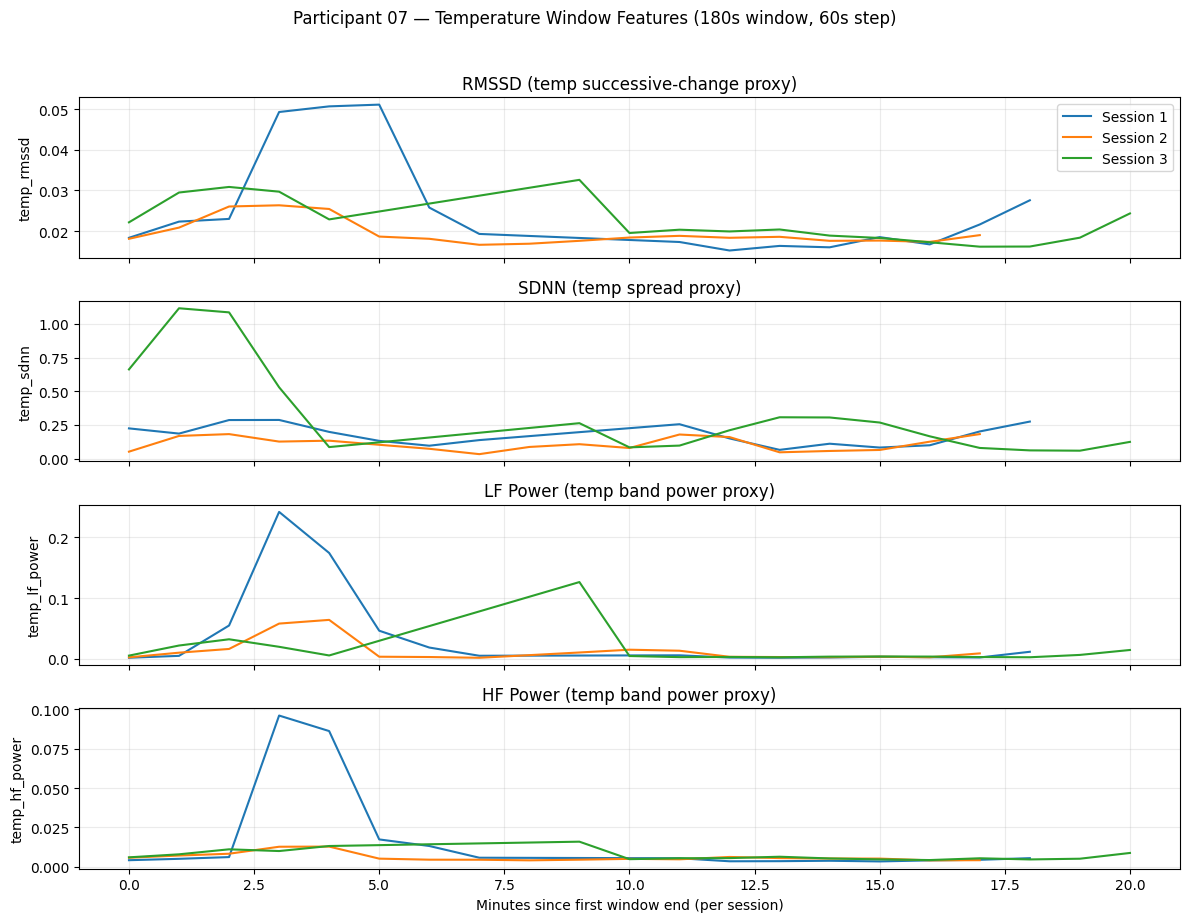

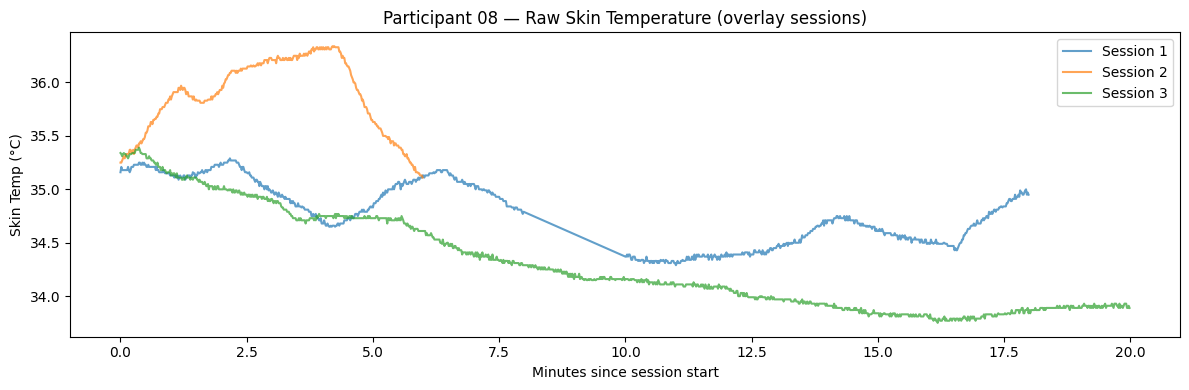

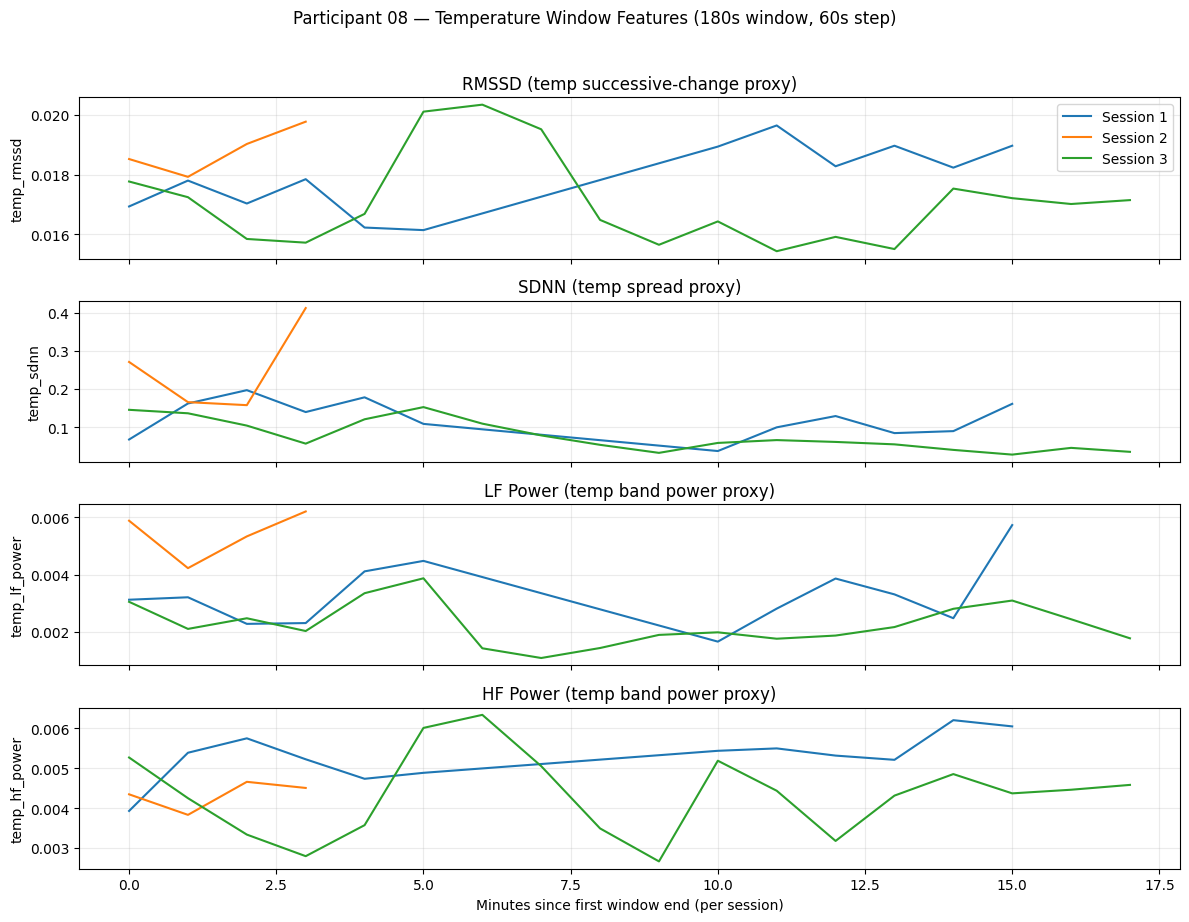

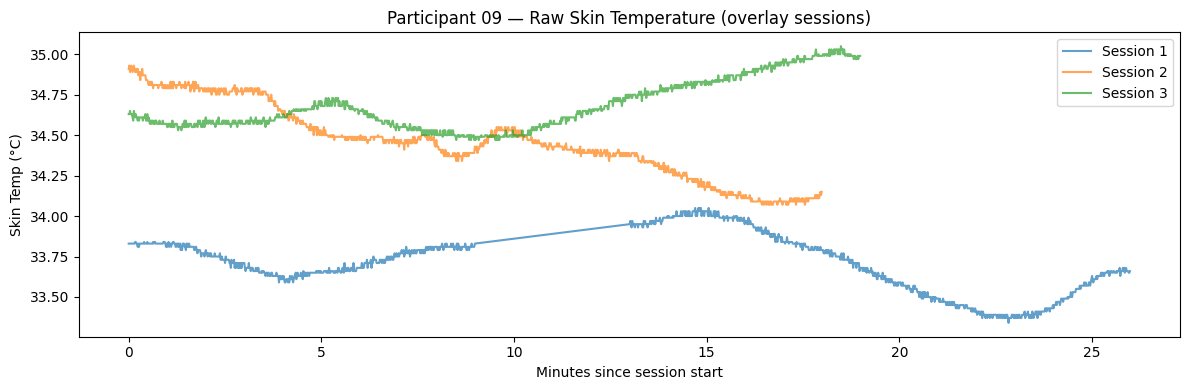

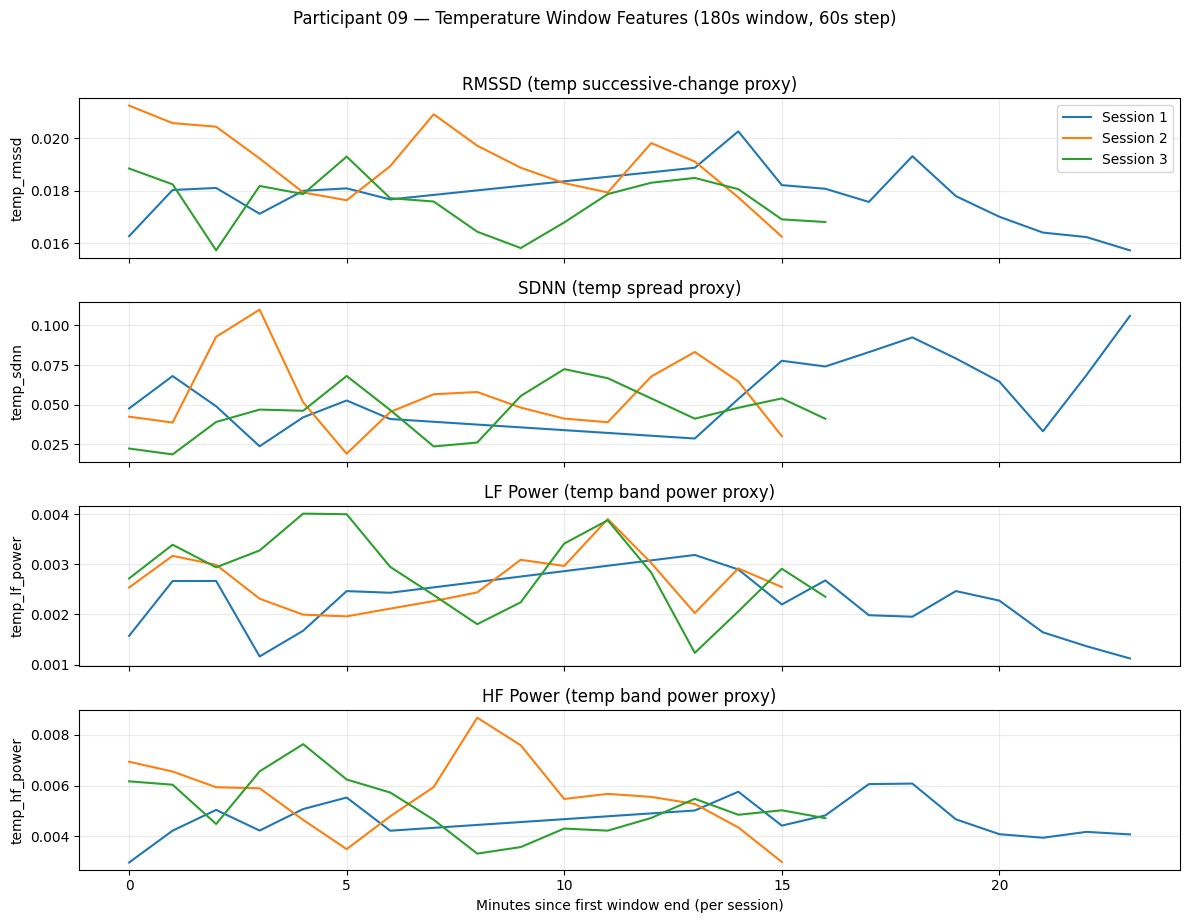

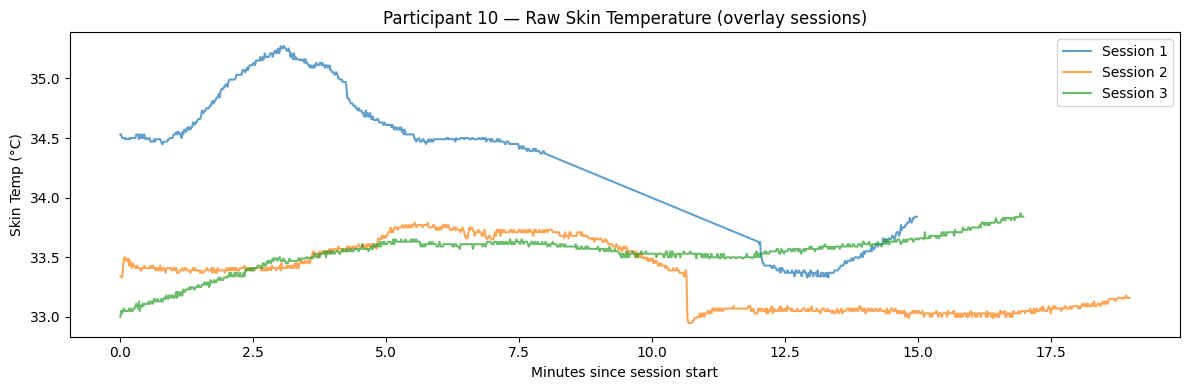

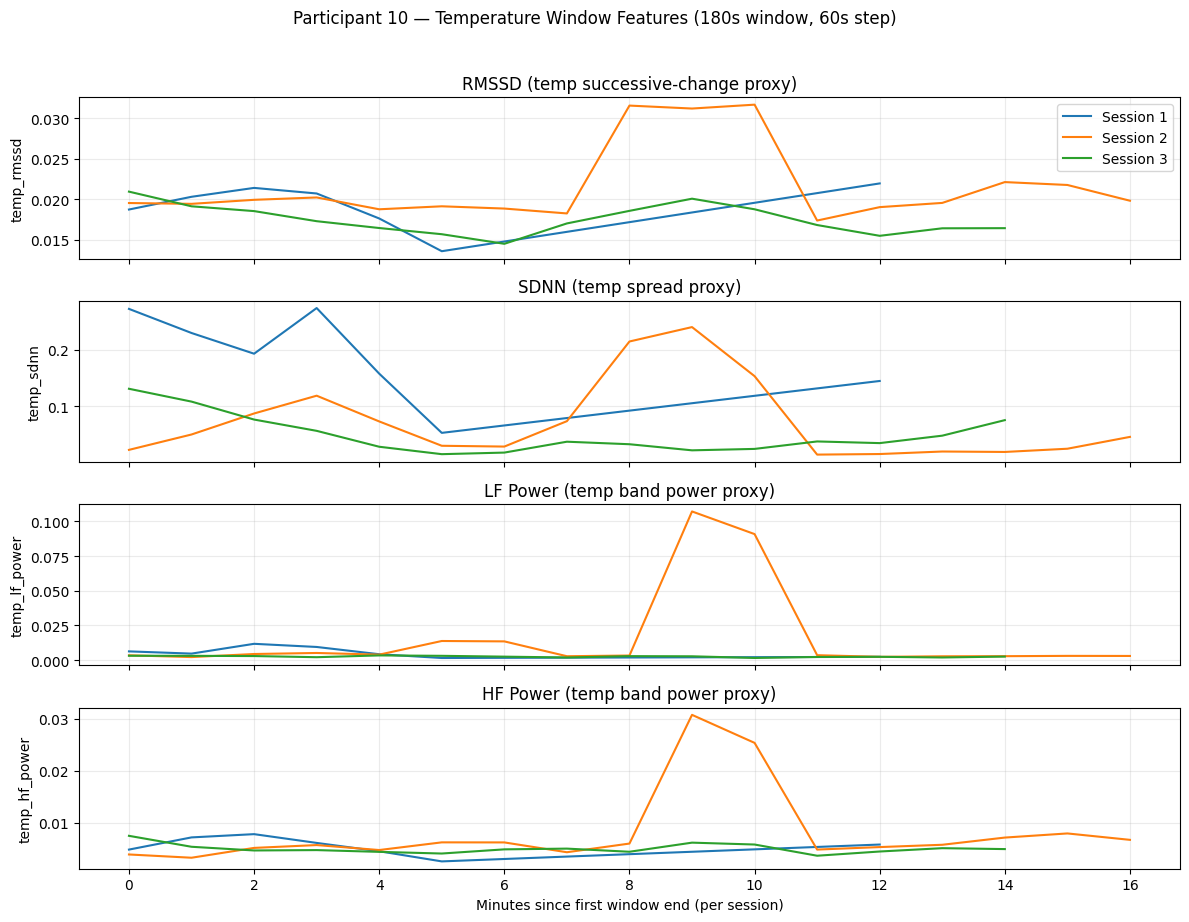

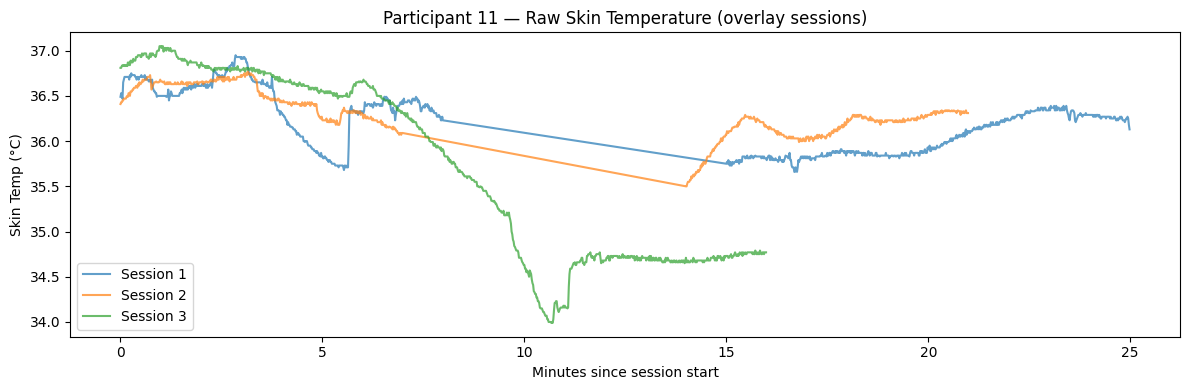

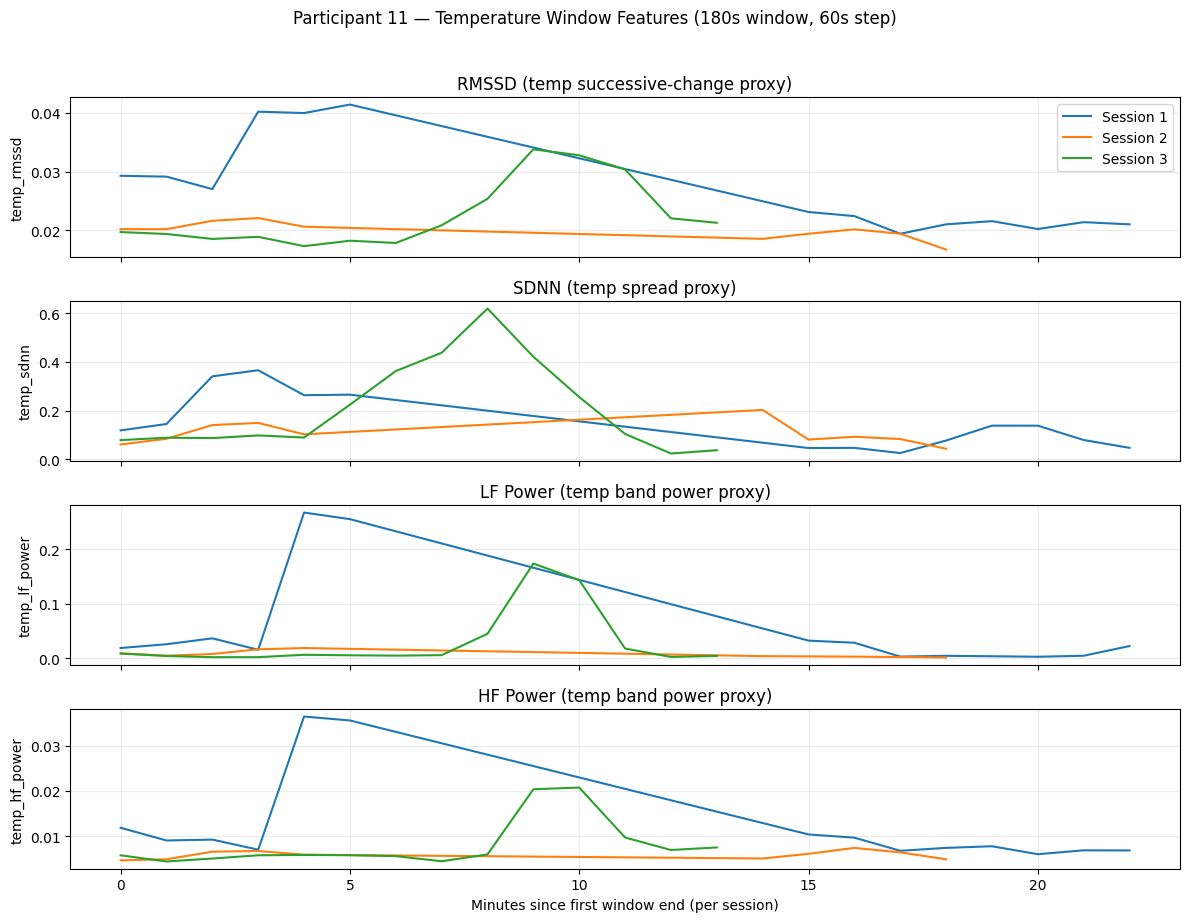

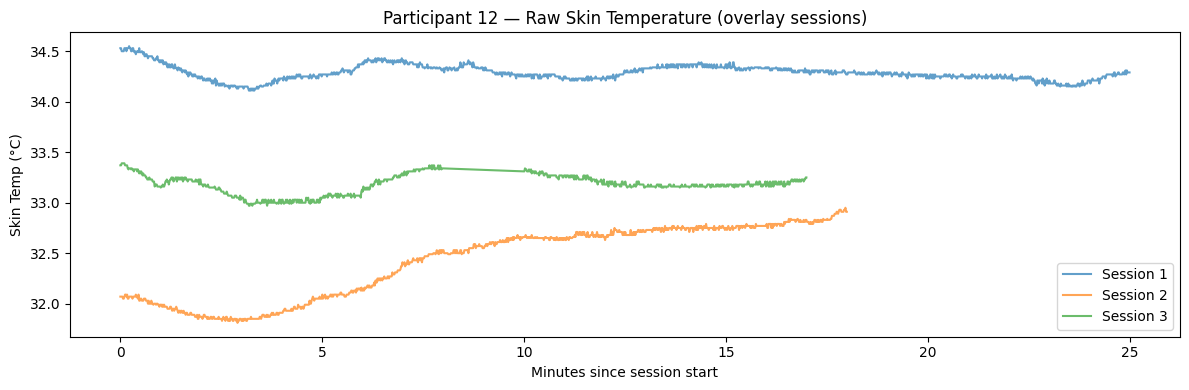

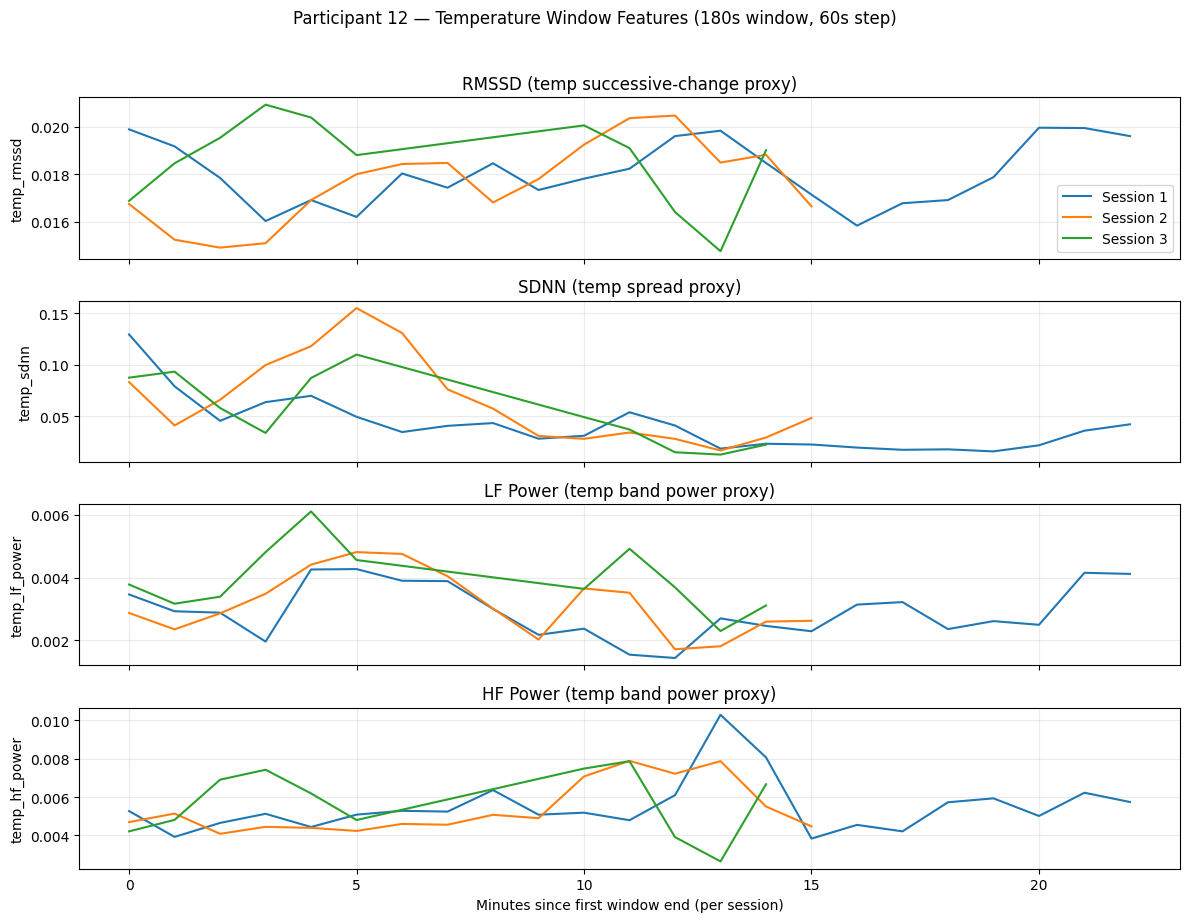

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch

def build_window_temp_feature_df(df_windows: pd.DataFrame) -> pd.DataFrame:
    gcols = ["participant", "session", "window_id"]
    rows = []

    for (pid, sid, wid), w in df_windows.groupby(gcols, sort=False):
        w = w.sort_values("timestamp")
        temp = w["skin_temp"].to_numpy(dtype=float)

        rmssd = _rmssd_proxy(temp)
        sdnn = _sdnn_proxy(temp)
        lf, hf = _lf_hf_power_proxy(temp, fs=1.0)

        rows.append({
            "participant": pid,
            "session": sid,
            "window_id": wid,
            "window_start": w["window_start"].iloc[0] if "window_start" in w.columns else w["timestamp"].iloc[0],
            "window_end": w["timestamp"].iloc[-1],

            "temp_rmssd": rmssd,
            "temp_sdnn": sdnn,
            "temp_lf_power": lf,
            "temp_hf_power": hf,
        })

    feat_df = pd.DataFrame(rows)

   
    feat_df["t_min"] = feat_df.groupby(["participant","session"])["window_end"].transform(
        lambda s: (s - s.min()).dt.total_seconds() / 60.0
    )
    return feat_df

df_temp_feats = build_window_temp_feature_df(df_windows)

print(df_temp_feats.shape)
print(df_temp_feats.head())

# 3) Plot per participant:
#    Fig A: raw skin temp (overlay sessions)
#    Fig B: engineered temp features (4 subplots, overlay sessions)
def plot_temp_participant(pid: int, df_windows: pd.DataFrame, df_temp_feats: pd.DataFrame):
    # --- Figure 1: raw TEMP ---
    plt.figure(figsize=(12, 4))
    subw = df_windows[df_windows["participant"] == pid]
    for sid, s in subw.groupby("session", sort=True):
        s = s.sort_values("timestamp")
        t_min = (s["timestamp"] - s["timestamp"].min()).dt.total_seconds() / 60.0
        plt.plot(t_min, s["skin_temp"], label=f"Session {sid}", alpha=0.7)

    plt.title(f"Participant {pid:02d} — Raw Skin Temperature (overlay sessions)")
    plt.xlabel("Minutes since session start")
    plt.ylabel("Skin Temp (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()

   
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    metrics = [
        ("temp_rmssd", "RMSSD (temp successive-change proxy)"),
        ("temp_sdnn", "SDNN (temp spread proxy)"),
        ("temp_lf_power", "LF Power (temp band power proxy)"),
        ("temp_hf_power", "HF Power (temp band power proxy)"),
    ]

    subf = df_temp_feats[df_temp_feats["participant"] == pid].copy()
    for ax, (col, title) in zip(axes, metrics):
        for sid, s in subf.groupby("session", sort=True):
            s = s.sort_values("t_min")
            ax.plot(s["t_min"], s[col], label=f"Session {sid}")
        ax.set_title(title)
        ax.set_ylabel(col)
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel("Minutes since first window end (per session)")
    axes[0].legend()
    fig.suptitle(f"Participant {pid:02d} — Temperature Window Features (180s window, 60s step)", y=1.02)
    plt.tight_layout()
    plt.show()

# Run plots for all participants
for pid in sorted(df_windows["participant"].unique()):
    plot_temp_participant(pid, df_windows, df_temp_feats)

Loading skin temperature data for all participants...
  P01 S1: 1579 seconds loaded
  P01 S2: 1341 seconds loaded
  P01 S3: 1324 seconds loaded
  P02 S1: 915 seconds loaded
  P02 S2: 1173 seconds loaded
  P02 S3: 1324 seconds loaded
  P03 S1: 1207 seconds loaded
  P03 S2: 1135 seconds loaded
  P03 S3: 1087 seconds loaded
  P04 S1: 1607 seconds loaded
  P04 S2: 1453 seconds loaded
  P04 S3: 1081 seconds loaded
  P05 S1: 1719 seconds loaded
  P05 S2: 1134 seconds loaded
  P05 S3: 1050 seconds loaded
  P06 S1: 1331 seconds loaded
  P06 S2: 1103 seconds loaded
  P06 S3: 1078 seconds loaded
  P07 S1: 1301 seconds loaded
  P07 S2: 1235 seconds loaded
  P07 S3: 1401 seconds loaded
  P08 S1: 1118 seconds loaded
  P08 S2: 677 seconds loaded
  P08 S3: 1236 seconds loaded
  P09 S1: 1563 seconds loaded
  P09 S2: 1250 seconds loaded
  P09 S3: 1142 seconds loaded
  P10 S1: 901 seconds loaded
  P10 S2: 1158 seconds loaded
  P10 S3: 1047 seconds loaded
  P11 S1: 1558 seconds loaded
  P11 S2: 1276 seco

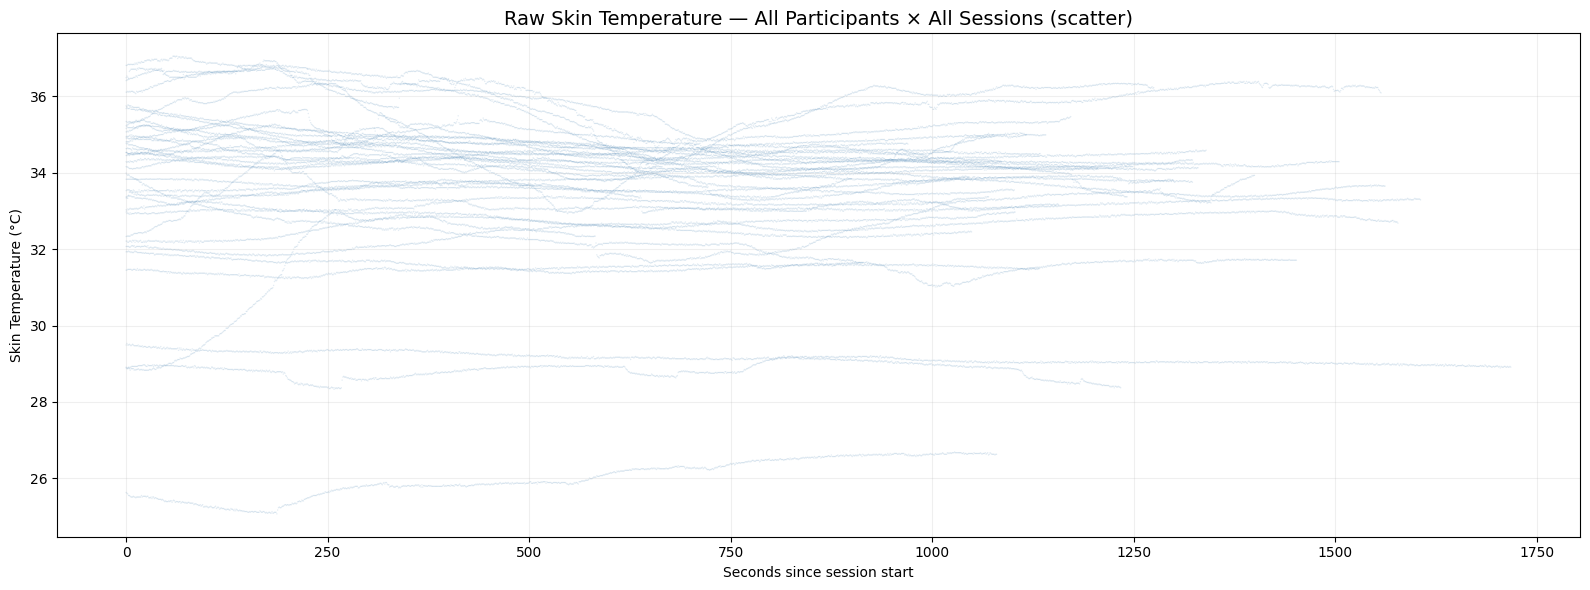


--- Plot 2: Scatter + median trend line ---


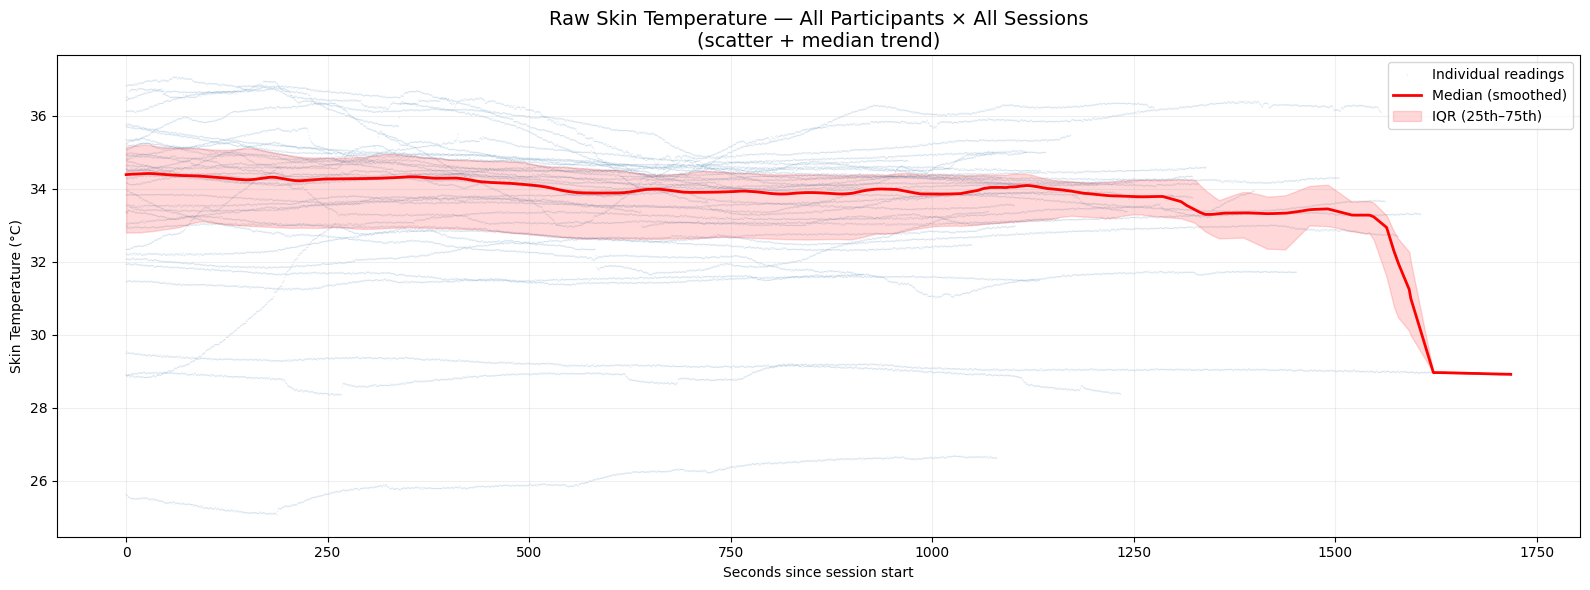


--- Plot 3: Colored by session ---


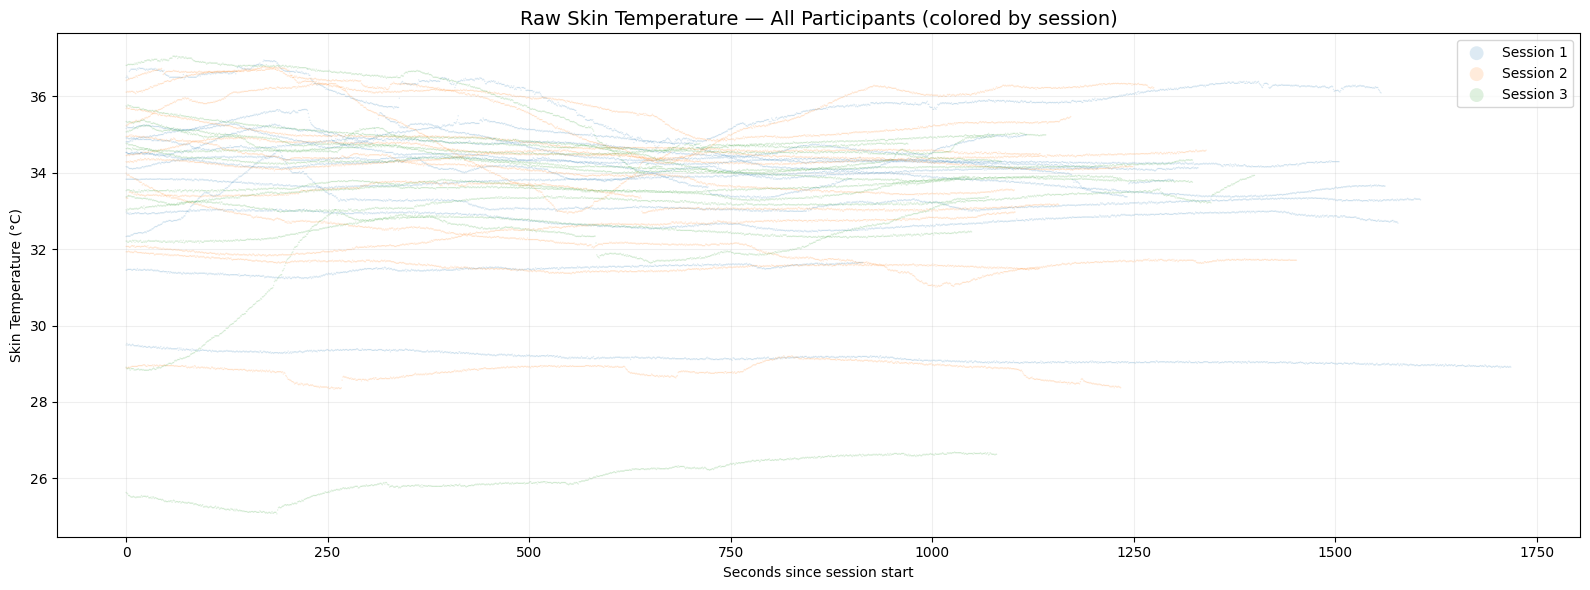


--- Plot 4: X-axis in minutes ---


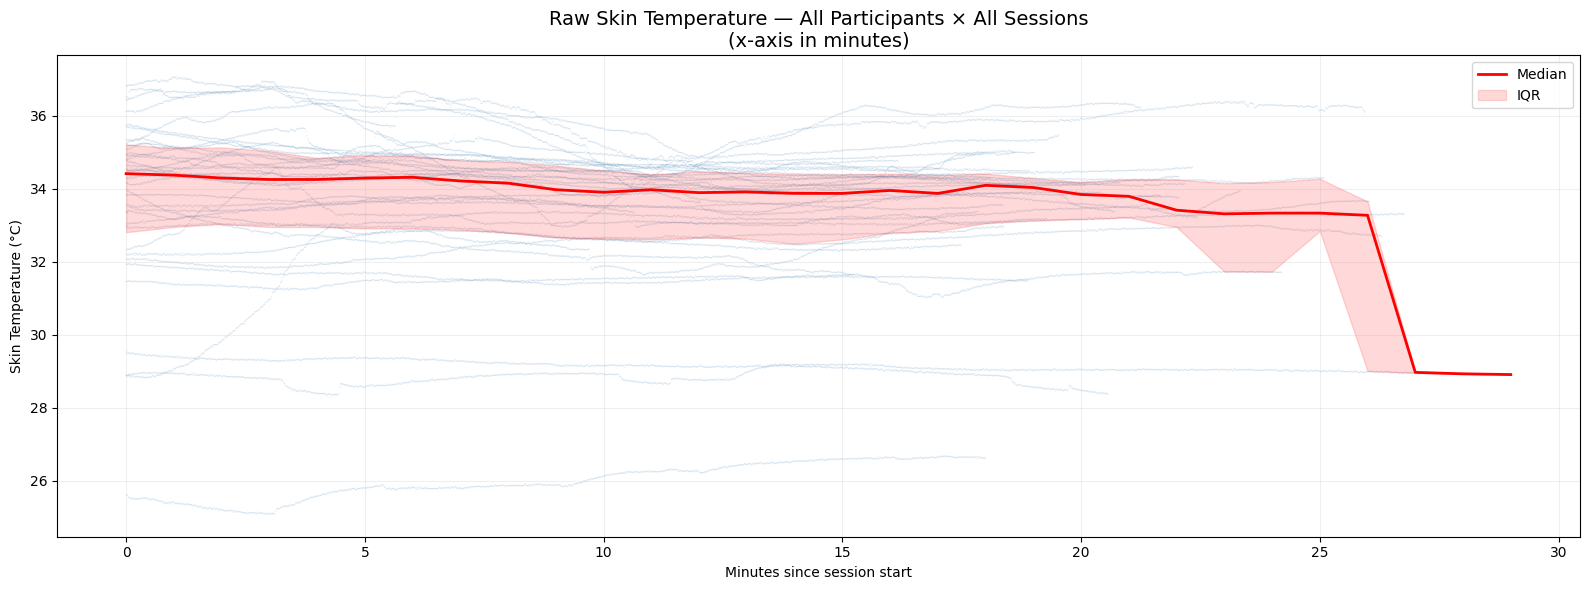


Done!


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]


def load_skin_temp(pid: int, sid: int) -> pd.DataFrame:
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"
 
    # Your special case
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"
 
    if not temp_file.exists():
        return pd.DataFrame()
 
    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
 
    # Rename column to consistent name
    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})
 
    # Resample to 1 Hz (1 second)
    df = (df.set_index("timestamp")
            .sort_index()
            .resample("1s")
            .mean(numeric_only=True)
            .dropna(subset=["skin_temp"])
            .reset_index())
 
    # Compute seconds from session start
    df["seconds"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds().astype(int)
 
    df["participant"] = pid
    df["session"] = sid
 
    return df[["seconds", "skin_temp", "participant", "session"]]
 

def load_all_temp() -> pd.DataFrame:
    all_dfs = []
    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df = load_skin_temp(pid, sid)
            if not df.empty:
                all_dfs.append(df)
                print(f"  P{pid:02d} S{sid}: {len(df)} seconds loaded")
            else:
                print(f"  P{pid:02d} S{sid}: [SKIP] no data")
 
    return pd.concat(all_dfs, ignore_index=True) if all_dfs else pd.DataFrame()
 
 

def plot_scatter_all(df: pd.DataFrame):
    """
    One dot per second per participant-session.
    This is the 'zoom out and see the pattern' plot.
    """
    plt.figure(figsize=(16, 6))
    plt.scatter(
        df["seconds"],
        df["skin_temp"],
        s=1,           # tiny dots so the overall pattern emerges
        alpha=0.15,    # transparent so overlapping dots form darker regions
        c="steelblue",
        edgecolors="none"
    )
    plt.title("Raw Skin Temperature — All Participants × All Sessions (scatter)", fontsize=14)
    plt.xlabel("Seconds since session start")
    plt.ylabel("Skin Temperature (°C)")
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()
 
 

def plot_scatter_with_trend(df: pd.DataFrame):
    """
    Same scatter, but add the median temperature at each second
    as a red line so you can clearly see the global trend.
    """
    fig, ax = plt.subplots(figsize=(16, 6))
 
    # Scatter (all dots)
    ax.scatter(
        df["seconds"],
        df["skin_temp"],
        s=1,
        alpha=0.15,
        c="steelblue",
        edgecolors="none",
        label="Individual readings"
    )
 
    # Compute median + IQR per second across all participants
    stats = df.groupby("seconds")["skin_temp"].agg(["median", "mean",
        lambda x: x.quantile(0.25),
        lambda x: x.quantile(0.75)
    ])
    stats.columns = ["median", "mean", "q25", "q75"]
    stats = stats.sort_index()
 
    # Smooth the median with a rolling window for cleaner trend line
    window = 30  # 30-second rolling average
    stats["median_smooth"] = stats["median"].rolling(window, center=True, min_periods=1).mean()
    stats["q25_smooth"] = stats["q25"].rolling(window, center=True, min_periods=1).mean()
    stats["q75_smooth"] = stats["q75"].rolling(window, center=True, min_periods=1).mean()
 
    # Plot trend
    ax.plot(stats.index, stats["median_smooth"], color="red", linewidth=2, label="Median (smoothed)")
    ax.fill_between(stats.index, stats["q25_smooth"], stats["q75_smooth"],
                     color="red", alpha=0.15, label="IQR (25th–75th)")
 
    ax.set_title("Raw Skin Temperature — All Participants × All Sessions\n(scatter + median trend)", fontsize=14)
    ax.set_xlabel("Seconds since session start")
    ax.set_ylabel("Skin Temperature (°C)")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()
 
 
def plot_scatter_by_session(df: pd.DataFrame):
    """
    Same scatter but dots colored by session number.
    Helps see if one session type consistently runs hotter/cooler.
    """
    colors = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
 
    plt.figure(figsize=(16, 6))
    for sid in SESSIONS:
        sub = df[df["session"] == sid]
        plt.scatter(
            sub["seconds"],
            sub["skin_temp"],
            s=1,
            alpha=0.15,
            c=colors[sid],
            edgecolors="none",
            label=f"Session {sid}"
        )
 
    plt.title("Raw Skin Temperature — All Participants (colored by session)", fontsize=14)
    plt.xlabel("Seconds since session start")
    plt.ylabel("Skin Temperature (°C)")
    plt.legend(markerscale=10)
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()
 
def plot_scatter_minutes(df: pd.DataFrame):
    """Same as Plot 2 but with x-axis in minutes."""
    df = df.copy()
    df["minutes"] = df["seconds"] / 60.0
 
    fig, ax = plt.subplots(figsize=(16, 6))
 
    ax.scatter(
        df["minutes"],
        df["skin_temp"],
        s=1,
        alpha=0.15,
        c="steelblue",
        edgecolors="none"
    )
 
    # Median trend per minute
    df["minute_bin"] = df["minutes"].round(0)
    stats = df.groupby("minute_bin")["skin_temp"].agg(["median",
        lambda x: x.quantile(0.25),
        lambda x: x.quantile(0.75)
    ])
    stats.columns = ["median", "q25", "q75"]
 
    ax.plot(stats.index, stats["median"], color="red", linewidth=2, label="Median")
    ax.fill_between(stats.index, stats["q25"], stats["q75"],
                     color="red", alpha=0.15, label="IQR")
 
    ax.set_title("Raw Skin Temperature — All Participants × All Sessions\n(x-axis in minutes)", fontsize=14)
    ax.set_xlabel("Minutes since session start")
    ax.set_ylabel("Skin Temperature (°C)")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()
 
 

print("Loading skin temperature data for all participants...")
df_all_temp = load_all_temp()
 
if df_all_temp.empty:
    print("[ERROR] No data loaded. Check DATA_ROOT path.")
else:
    print(f"\nTotal data points: {len(df_all_temp)}")
    print(f"Participants: {sorted(df_all_temp['participant'].unique())}")
    print(f"Temperature range: {df_all_temp['skin_temp'].min():.1f}°C to {df_all_temp['skin_temp'].max():.1f}°C")
 
    print("\n--- Plot 1: Raw scatter (zoom out to see pattern) ---")
    plot_scatter_all(df_all_temp)
 
    print("\n--- Plot 2: Scatter + median trend line ---")
    plot_scatter_with_trend(df_all_temp)
 
    print("\n--- Plot 3: Colored by session ---")
    plot_scatter_by_session(df_all_temp)
 
    print("\n--- Plot 4: X-axis in minutes ---")
    plot_scatter_minutes(df_all_temp)
 
    print("\nDone!")

# Integrating features into the dataset

In [6]:
import numpy as np
from scipy.signal import welch
from scipy.stats import skew, iqr, median_abs_deviation

In [7]:
def safe_cv(x):
    mu = np.nanmean(x)
    return np.nanstd(x) / mu if mu != 0 else np.nan


def spectral_features(x, fs=1.0):
    """
    Returns (spectral_centroid, spectral_entropy)
    """
    x = np.asarray(x)
    x = x[np.isfinite(x)]
    if len(x) < 10:
        return np.nan, np.nan

    freqs, psd = welch(x, fs=fs, nperseg=min(len(x), 64))
    psd = np.maximum(psd, 1e-12)
    psd_norm = psd / psd.sum()

    centroid = np.sum(freqs * psd_norm)
    entropy = -np.sum(psd_norm * np.log2(psd_norm))

    return centroid, entropy


def diff_stats(x):
    d1 = np.diff(x)
    d2 = np.diff(d1)

    return {
        "std_diff": np.nanstd(d1),
        "mean_abs_diff": np.nanmean(np.abs(d1)),
        "std_d2": np.nanstd(d2),
        "mean_abs_d2": np.nanmean(np.abs(d2)),
    }

In [8]:
def extract_hrv_features(hrv):
    hrv = np.asarray(hrv)

    feats = {}
    feats["hrv_cv"] = safe_cv(hrv)
    feats["hrv_skew"] = skew(hrv, nan_policy="omit")

    # RMSSD-style proxy (on HRV series, not RR)
    diffs = np.diff(hrv)
    feats["hrv_rmssd"] = np.sqrt(np.nanmean(diffs**2))

    feats.update({f"hrv_{k}": v for k, v in diff_stats(hrv).items()})

    # spectral (1 Hz signal)
    centroid, entropy = spectral_features(hrv, fs=1.0)
    feats["hrv_spectral_centroid"] = centroid
    feats["hrv_spectral_entropy"] = entropy

    # LF / HF normalized power (proxy bands)
    freqs, psd = welch(hrv, fs=1.0, nperseg=min(len(hrv), 64))
    lf = (freqs >= 0.04) & (freqs < 0.15)
    hf = (freqs >= 0.15) & (freqs < 0.40)

    lf_power = np.nansum(psd[lf])
    hf_power = np.nansum(psd[hf])
    total = lf_power + hf_power

    feats["hrv_lf_nu"] = lf_power / total if total > 0 else np.nan
    feats["hrv_hf_nu"] = hf_power / total if total > 0 else np.nan

    return feats

In [9]:
def extract_temp_features(temp):
    temp = np.asarray(temp)

    feats = {}
    feats["temp_mean"] = np.nanmean(temp)
    feats["temp_std"] = np.nanstd(temp)
    feats["temp_cv"] = safe_cv(temp)

    feats["temp_p95_p5"] = np.nanpercentile(temp, 95) - np.nanpercentile(temp, 5)
    feats["temp_iqr"] = iqr(temp, nan_policy="omit")
    feats["temp_mad"] = median_abs_deviation(temp, nan_policy="omit")

    centroid, entropy = spectral_features(temp, fs=1.0)
    feats["temp_spectral_centroid"] = centroid
    feats["temp_spectral_entropy"] = entropy

    return feats

In [10]:
def build_feature_table(df_windows):
    rows = []

    for (pid, sid, wid), w in df_windows.groupby(
        ["participant", "session", "window_id"]
    ):
        row = {
            "participant": pid,
            "session": sid,
            "window_id": wid,
            "window_start": w["window_start"].iloc[0],
            "window_end": w["timestamp"].iloc[-1],
        }

        row.update(extract_hrv_features(w["hrv"].values))
        row.update(extract_temp_features(w["skin_temp"].values))

        rows.append(row)

    return pd.DataFrame(rows)

In [11]:
df_features = build_feature_table(df_windows)
print(df_features.shape)
df_features.head()

(533, 24)


,participant,session,window_id,window_start,window_end,hrv_cv,hrv_skew,hrv_rmssd,hrv_std_diff,hrv_mean_abs_diff,...,hrv_lf_nu,hrv_hf_nu,temp_mean,temp_std,temp_cv,temp_p95_p5,temp_iqr,temp_mad,temp_spectral_centroid,temp_spectral_entropy
0,1,1,0,2021-08-19 10:53:43+00:00,2021-08-19 10:56:42+00:00,0.038637,-2.441309,0.279665,0.276070,0.078212,...,0.858996,0.141004,32.989833,0.036946,0.001120,0.10,0.08,0.03,0.150816,4.144112
1,1,1,1,2021-08-19 10:54:43+00:00,2021-08-19 10:57:42+00:00,0.057895,-0.319180,0.388379,0.386405,0.128492,...,0.926558,0.073442,33.010944,0.018729,0.000567,0.04,0.03,0.01,0.189433,4.666058
2,1,1,2,2021-08-19 10:55:43+00:00,2021-08-19 10:58:42+00:00,0.076361,-0.553973,0.409387,0.408777,0.145251,...,0.928229,0.071771,32.989889,0.034625,0.001050,0.10,0.08,0.03,0.167198,4.380848
3,1,1,3,2021-08-19 10:56:43+00:00,2021-08-19 10:59:42+00:00,0.059505,-1.262117,0.409387,0.405557,0.145251,...,0.914986,0.085014,32.969611,0.031979,0.000970,0.10,0.05,0.02,0.152062,4.148625
4,1,1,4,2021-08-19 10:57:43+00:00,2021-08-19 11:00:42+00:00,0.022190,0.485025,0.269492,0.268970,0.072626,...,0.848211,0.151789,32.945722,0.017827,0.000541,0.06,0.02,0.02,0.222121,4.807858
